# Transformer-Based Police Narrative Classification with an LLM Assistant
**MAAI 902 – Natural Language Processing & LLMs · Applied NLP Project**
Navi Dharshan B · University of Wollongong in Dubai

**Research question:** How effectively can a fine-tuned BERT model classify police encounter narratives into the
existing *Stopped*, *Encountered* and *Observed* categories compared with traditional machine-learning methods?

**Dataset:** Boston Police Department 2024 Field Interrogation and Observation (FIO) records, `2024_annual_fio.csv`
(Analyze Boston, PDDL licence). Only the record-level file is used; the person-level file (`2024_annual_fio_name.csv`)
is deliberately excluded because it holds demographic data about individuals.

| Part | Content |
|---|---|
| Phase 1 | Data inspection, leakage checks, cleaning, privacy redaction (rules + spaCy NER), train/validation/test split |
| Phase 2 | TF-IDF + Logistic Regression baseline, with a keyword-masked ablation |
| Phase 3 | BERT fine-tuning (3 seeds) with the same ablation |
| Phase 4 | Model comparison, McNemar test, error analysis |
| Phase 5 | RAG assistant: Rule 323 + FIO data key + project cards, hybrid retrieval, Qwen2.5-1.5B-Instruct, evaluation |
| Phase 6 | Streamlit application with a public link |

**How to run:** Runtime → Change runtime type → **T4 GPU**, then Run all. Upload `2024_annual_fio.csv` when asked
(Phase 1) and `rule323.pdf` + `fiokeymark43-1-1.xlsx` (Phase 5). A full run takes about 45 minutes.

*All outputs shown come from one complete Colab T4 run on 19 October 2026 (about 45 minutes).*

## 0. Setup

In [52]:
# spaCy is pre-installed on Colab; this makes sure the small English model is present.
import importlib.util, subprocess, sys
if importlib.util.find_spec("en_core_web_sm") is None:
    subprocess.run([sys.executable, "-m", "spacy", "download", "en_core_web_sm"], check=False)

In [2]:
import os, re, json, random
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 42
random.seed(SEED); np.random.seed(SEED)

LABELS = ["Stopped", "Encountered", "Observed"]   # fixed label order used everywhere
TEXT_COL, TARGET_COL = "contact_reason", "circumstance"
OUT_DIR = "outputs"; os.makedirs(OUT_DIR, exist_ok=True)
pd.set_option("display.max_colwidth", 200)

## Phase 1 – Data preparation
### 1.1 Load the dataset
Upload `2024_annual_fio.csv` with the **Files** panel on the left (or run the cell and pick the file when prompted).
The file starts with a byte-order mark, so it is read with `utf-8-sig`.

In [3]:
DATA_PATH = "2024_annual_fio.csv"

if not os.path.exists(DATA_PATH):
    try:
        from google.colab import files          # only available on Colab
        uploaded = files.upload()
        DATA_PATH = next(iter(uploaded))
    except ImportError:
        raise FileNotFoundError(f"Put {DATA_PATH} next to this notebook.")

df_raw = pd.read_csv(DATA_PATH, encoding="utf-8-sig")
print("Shape:", df_raw.shape)
df_raw.dtypes.to_frame("dtype").T

Saving 2024_annual_fio.csv to 2024_annual_fio.csv
Shape: (4860, 21)


,fc_num,contact_date,contact_officer,contact_officer_name,supervisor,supervisor_name,street,city,state,zip,...,circumstance,basis,vehicle_year,vehicle_state,vehicle_mode,vehicle_color,vehicle_style,vehicle_type,key_situations,contact_reason
dtype,object,object,object,object,int64,object,object,object,object,int64,...,object,object,float64,object,object,object,object,object,object,object


### 1.2 Structure and missing values
Officer, supervisor and street columns are identifying information that the classifier does not need,
so they are never displayed or used as model inputs.

In [4]:
NOT_FOR_MODELLING = ["contact_officer", "contact_officer_name", "supervisor", "supervisor_name", "street"]

missing = (df_raw.isna().sum().to_frame("missing")
           .assign(pct=lambda d: (d.missing / len(df_raw) * 100).round(1))
           .sort_values("missing", ascending=False))
display(missing[missing.missing > 0])

print("Exact duplicate rows:     ", df_raw.duplicated().sum())
print("Duplicate fc_num:         ", df_raw["fc_num"].duplicated().sum())
print("Empty narratives:         ", (df_raw[TEXT_COL].fillna("").str.strip() == "").sum())
print("Duplicate narrative texts:", df_raw[TEXT_COL].duplicated().sum())

,missing,pct
duration,3603,74.1
vehicle_style,3330,68.5
vehicle_state,3237,66.6
vehicle_color,3080,63.4
vehicle_year,3047,62.7
vehicle_type,2965,61.0
vehicle_mode,2965,61.0
street,1304,26.8
key_situations,674,13.9
basis,12,0.2


Exact duplicate rows:      0
Duplicate fc_num:          239
Empty narratives:          3
Duplicate narrative texts: 241


### 1.3 Target categories and class imbalance

,records,share_%
circumstance,,
Stopped,3042,62.6
Encountered,1152,23.7
Observed,666,13.7


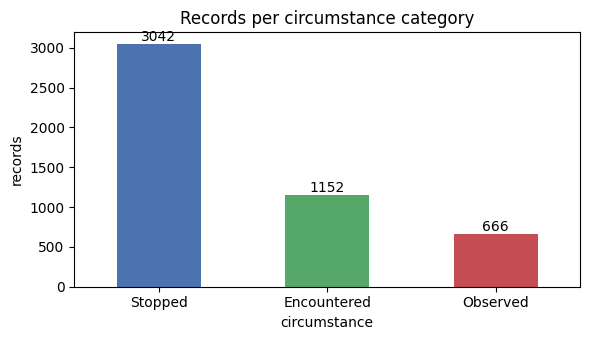

In [5]:
counts = df_raw[TARGET_COL].value_counts().reindex(LABELS)
display(pd.DataFrame({"records": counts, "share_%": (counts / counts.sum() * 100).round(1)}))

ax = counts.plot.bar(color=["#4C72B0", "#55A868", "#C44E52"], rot=0, figsize=(6, 3.5))
ax.set_title("Records per circumstance category"); ax.set_ylabel("records")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/class_distribution.png", dpi=150); plt.show()

### 1.4 Narrative length

,count,mean,std,min,25%,50%,75%,max
circumstance,,,,,,,,
Stopped,3042.0,114.3,72.6,0.0,66.0,97.0,142.0,1065.0
Encountered,1152.0,103.5,69.1,7.0,62.0,89.0,128.0,1070.0
Observed,666.0,98.2,64.7,2.0,56.0,84.5,125.0,550.0


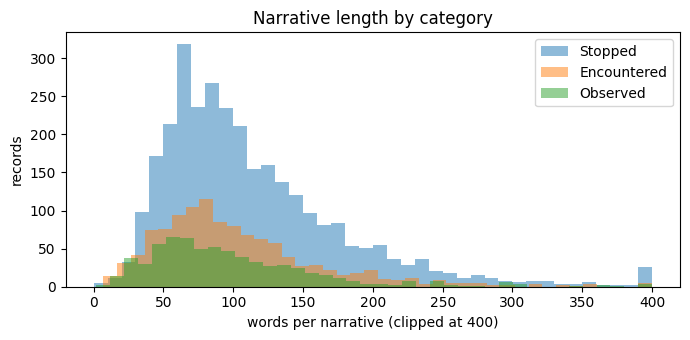

Narratives over 380 words (likely to exceed BERT's 512 tokens): 36


In [6]:
df_raw["n_words"] = df_raw[TEXT_COL].fillna("").str.split().str.len()
display(df_raw.groupby(TARGET_COL)["n_words"].describe().reindex(LABELS).round(1))

fig, ax = plt.subplots(figsize=(7, 3.5))
for lab in LABELS:
    ax.hist(df_raw.loc[df_raw[TARGET_COL] == lab, "n_words"].clip(upper=400), bins=40, alpha=0.5, label=lab)
ax.set_xlabel("words per narrative (clipped at 400)"); ax.set_ylabel("records"); ax.legend()
ax.set_title("Narrative length by category")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/length_distribution.png", dpi=150); plt.show()

print(f"Narratives over 380 words (likely to exceed BERT's 512 tokens): {(df_raw.n_words > 380).sum()}")

### 1.5 Leakage checks
Two risks are checked before any modelling:
1. **Label words in the text** – officers may write "stopped" or "observed" in the narrative.
2. **Other columns tied to the label** – e.g. `basis` (legal basis for the contact).

In [7]:
keywords = {"stop": r"\bstop", "encounter": r"\bencount", "observe": r"\bobserv",
            "frisk": r"\bfrisk", "traffic": r"\btraffic", "vehicle": r"\bvehicle"}
low = df_raw[TEXT_COL].fillna("").str.lower()
kw = pd.DataFrame({k: low.str.contains(p, regex=True) for k, p in keywords.items()})
kw[TARGET_COL] = df_raw[TARGET_COL]
kw_rates = (kw.groupby(TARGET_COL).mean() * 100).round(1).reindex(LABELS)
print("% of narratives in each category containing the keyword:")
display(kw_rates)

% of narratives in each category containing the keyword:


,stop,encounter,observe,frisk,traffic,vehicle
circumstance,,,,,,
Stopped,62.6,7.3,49.5,29.5,19.5,43.3
Encountered,13.9,33.3,43.1,6.5,4.6,16.5
Observed,14.7,6.3,83.9,2.0,8.1,38.6


In [8]:
basis_tab = pd.crosstab(df_raw["basis"].fillna("Missing"), df_raw[TARGET_COL])[LABELS]
display(basis_tab)
print("`basis` is strongly associated with the label (e.g. Probable Cause -> Stopped),")
print("so only the narrative text is used as model input.")

circumstance,Stopped,Encountered,Observed
basis,,,
Encounter,156,530,167
Intel,217,305,392
Missing,5,1,6
Probable Cause,1462,121,26
Reasonable Suspicion,1202,195,75


`basis` is strongly associated with the label (e.g. Probable Cause -> Stopped),
so only the narrative text is used as model input.


### 1.6 Cleaning
* keep only `fc_num`, the narrative and the label
* drop empty narratives
* drop repeated narratives **before** splitting, so identical texts cannot appear in both train and test
* normalise the source's own masks: the data publisher replaced names with `XXX`, often glued to the next word
  (`XXXwas`, `observedXXX`, `XX/XX/XXXX`). These become a separate `[REDACTED]` token so the real words survive
* normalise whitespace

In [9]:
df = df_raw[["fc_num", TEXT_COL, TARGET_COL]].copy()
MASK_RX = re.compile(r"X{2,}(?:\s*[/\-]\s*X{2,})*")
df[TEXT_COL] = (df[TEXT_COL].fillna("")
                .str.replace(MASK_RX, " [REDACTED] ", regex=True)
                .str.replace(r"(?:\[REDACTED\]\s*){2,}", "[REDACTED] ", regex=True)
                .str.replace(r"\s+", " ", regex=True).str.strip())

n0 = len(df)
df = df[df[TEXT_COL] != ""]
n_empty = n0 - len(df)

conflicts = df.groupby(TEXT_COL)[TARGET_COL].nunique().gt(1).sum()
n1 = len(df)
df = df.drop_duplicates(subset=TEXT_COL, keep="first").reset_index(drop=True)
n_dup = n1 - len(df)

print(f"Removed {n_empty} empty and {n_dup} duplicate narratives "
      f"({conflicts} duplicates had conflicting labels). Remaining: {len(df)}")
display(df[TARGET_COL].value_counts().reindex(LABELS).to_frame("records after cleaning"))

Removed 3 empty and 241 duplicate narratives (1 duplicates had conflicting labels). Remaining: 4616


,records after cleaning
circumstance,
Stopped,2917
Encountered,1074
Observed,625


### 1.7 Privacy redaction
Names of the people involved are already masked by the publisher (now `[REDACTED]`). The narratives still contain
**officer names**, streets and neighbourhoods. Redaction runs in two passes:

1. **Rules first** (precise, checked against the data):
   * officer and supervisor names, taken from the dataset's own `contact_officer_name` / `supervisor_name` columns.
     Name words that also appear as ordinary lower-case words in the narratives (*white, hill, brown, long, mark…*)
     are excluded so descriptions are not erased. Removing officer names also prevents the model learning
     *which officer wrote the report* instead of *what happened*.
   * street addresses, Boston neighbourhood names and phone numbers.
2. **spaCy NER second** for remaining people and places, with a filter for its known false positives on police text
   (job titles such as *Det* or *Sgt*, offence words such as *Larceny* or *Assault*, "pat" in *pat frisk*,
   state codes such as *MA Reg*, and unit call signs such as *B102F*).

All names become `[PERSON]`; streets and areas become `[ADDRESS]` or `[PLACE]`. The redacted text is used for every model.

In [10]:
nlp = spacy.load("en_core_web_sm")

# ---- Pass 1: rules ---------------------------------------------------------------
# Officer / supervisor name words from the record columns
name_words = set()
for col in ["contact_officer_name", "supervisor_name"]:
    for v in df_raw[col].dropna().astype(str):
        for w in re.split(r"[,\s]+", v):
            w = w.strip(".").lower()
            if len(w) > 2:
                name_words.add(w)

# Words that are also ordinary vocabulary in the narratives (e.g. "white", "hill") are kept
lower_vocab = pd.Series(re.findall(r"\b[a-z][a-z'\-]+\b", " ".join(df[TEXT_COL]))).value_counts()
common_words = {w for w in name_words if lower_vocab.get(w, 0) >= 3}
officer_words = name_words - common_words
print(f"Officer/supervisor name words: {len(name_words)} (kept as ordinary words: {sorted(common_words)})")

CAP_WORD = re.compile(r"\b[A-Z][A-Za-z'\-]+\b")
NEIGHBOURHOODS = ("Allston|Brighton|Back Bay|Bay Village|Beacon Hill|Charlestown|Chinatown|Dorchester|Downtown|"
                  "East Boston|Fenway|Hyde Park|Jamaica Plain|Mattapan|Mission Hill|North End|Roslindale|Roxbury|"
                  "South Boston|South End|West End|West Roxbury|Leather District|Longwood")
STREET_TYPES = "St|Street|Ave|Avenue|Rd|Road|Blvd|Pl|Place|Sq|Square|Ter|Terrace|Way|Ct|Court|Dr|Drive|Pk|Park|Hwy"
RULES = [
    ("[ADDRESS]", re.compile(rf"\b(?:\d{{1,5}}\s+)?(?:[A-Z][a-z]+\s){{1,3}}(?:{STREET_TYPES})\b\.?")),
    ("[PLACE]",   re.compile(rf"\b(?:{NEIGHBOURHOODS})\b", re.I)),
    ("[PHONE]",   re.compile(r"\b\(?\d{3}\)?[-. ]?\d{3}[-. ]\d{4}\b")),
]

redaction_counts = {"officer names": 0, "[ADDRESS]": 0, "[PLACE] rules": 0, "[PHONE]": 0,
                    "[PERSON] spaCy": 0, "[PLACE] spaCy": 0}

def redact_rules(text):
    def officer(m):
        if m.group(0).lower() in officer_words:
            redaction_counts["officer names"] += 1
            return "[PERSON]"
        return m.group(0)
    text = CAP_WORD.sub(officer, text)
    for tag, rx in RULES:
        text, n = rx.subn(tag, text)
        redaction_counts[tag if tag != "[PLACE]" else "[PLACE] rules"] += n
    return text

# ---- Pass 2: spaCy NER with a false-positive filter --------------------------------
ENT_TAGS = {"PERSON": "[PERSON]", "GPE": "[PLACE]", "LOC": "[PLACE]", "FAC": "[PLACE]"}
DOMAIN_TERMS = {
    "officer", "officers", "det", "detective", "sgt", "sergeant", "lt", "capt", "po", "trooper", "pat", "frisk",
    "driver", "operator", "passenger", "vehicle", "victim", "suspect", "subject", "larceny", "assault", "poss",
    "possession", "robbery", "rape", "warrant", "firearm", "gun", "drug", "drugs", "trespass", "shooting", "bwc",
    "activated", "reg", "bolo", "cjis", "intel", "safety", "gang", "fio", "ma", "us", "bb",
    "redacted", "person", "place", "address", "phone",
    "marijuana", "escape", "larcenies", "burglary", "premises", "ordinance", "district", "detectives",
    "mark", "breaking", "entering", "trafficking", "distribution", "unit", "dispatch",
}
UNIT_CODE = re.compile(r"^[A-Z]{1,2}\d{2,3}[A-Z]$")

def is_false_positive(ent):
    words = {w.lower().strip(".'") for w in ent.text.split()}
    return (bool(words & DOMAIN_TERMS) or bool(UNIT_CODE.match(ent.text)) or "[" in ent.text
            or any(ch.isdigit() for ch in ent.text))          # district / system codes such as "District B3"

skipped = Counter()

def redact_ner(doc):
    text, out, last = doc.text, [], 0
    for ent in doc.ents:
        if ent.label_ not in ENT_TAGS:
            continue
        if is_false_positive(ent):
            skipped[ent.text] += 1
            continue
        out.append(text[last:ent.start_char]); out.append(ENT_TAGS[ent.label_])
        redaction_counts["[PERSON] spaCy" if ent.label_ == "PERSON" else "[PLACE] spaCy"] += 1
        last = ent.end_char
    out.append(text[last:])
    return "".join(out)

rule_texts = [redact_rules(t) for t in df[TEXT_COL]]
docs = list(nlp.pipe(rule_texts, batch_size=64, disable=["parser"]))
df["text_redacted"] = [redact_ner(d) for d in docs]

print("Redactions made:", redaction_counts)
print("Narratives changed by redaction:", (df.text_redacted != df[TEXT_COL]).sum(), "of", len(df))
print("spaCy entities kept because they are police/legal terms (top 15):", skipped.most_common(15))

Officer/supervisor name words: 1050 (kept as ordinary words: ['ball', 'bang', 'beard', 'bent', 'brown', 'green', 'hill', 'holder', 'jean', 'king', 'long', 'mark', 'van', 'white', 'woods'])
Redactions made: {'officer names': 8883, '[ADDRESS]': 8197, '[PLACE] rules': 1398, '[PHONE]': 0, '[PERSON] spaCy': 1112, '[PLACE] spaCy': 1991}
Narratives changed by redaction: 4454 of 4616
spaCy entities kept because they are police/legal terms (top 15): [('Officers', 199), ('Det', 176), ('MA', 165), ('MA Reg', 145), ('Pat', 79), ('Larceny', 59), ('Assault', 54), ('Sgt', 53), ('Driver', 48), ('PO', 47), ('MA REG', 42), ('Ma Reg', 40), ('Vehicle', 39), ('BWC Activated', 39), ('B102F', 38)]


#### 1.7a Redaction check
What spaCy still replaces, and three redacted examples. Review these before training; report the counts in the
privacy section of the report.

In [11]:
for label in ["PERSON", "GPE", "LOC", "FAC"]:
    c = Counter(e.text for d in docs for e in d.ents if e.label_ == label and not is_false_positive(e))
    print(f"{label} redacted – {sum(c.values())} total, top 15: {c.most_common(15)}")

print()
for t in df.sample(3, random_state=SEED).text_redacted:
    print("-", t[:300], "\n")

PERSON redacted – 1112 total, top 15: [('Cass', 22), ('Melnea Cass', 18), ('Rob', 12), ('Lynn', 11), ('Walgreens', 11), ('Nissan Altima', 10), ('Morton', 10), ('Milaiko', 10), ('Evelyn', 9), ('Garfield', 9), ('Ellsworth', 9), ('Brown', 8), ('Caller', 8), ('grey hoodie', 7), ('Everett', 7)]
GPE redacted – 1526 total, top 15: [('Boston', 444), ('Massachusetts', 76), ('Washington', 52), ('Cambridge', 35), ('Brockton', 26), ('Florida', 23), ('Tremont', 22), ('Somerville', 19), ('Lenox', 18), ('South Station', 15), ('New Hampshire', 14), ('New York', 13), ('Albany', 13), ('St.', 12), ('Apt', 11)]
LOC redacted – 178 total, top 15: [('Battery', 13), ('Mt. Pleasant', 11), ('South Bay', 9), ('South', 7), ('the South Bay Mall', 7), ('Franklin Field', 5), ('Magnolia', 4), ('North Face', 4), ('Liberty Plaza', 3), ('Bunker Hill', 3), ('South Bay Mall', 3), ('West Broadway', 3), ('Park', 3), ('Weymouth', 3), ('Fall River', 3)]
FAC redacted – 287 total, top 15: [('Suffolk Superior', 25), ('Franklin F

### 1.8 Linguistic preprocessing for the TF-IDF baseline
BERT receives the redacted text as written (its own tokenizer handles casing and sub-words).
The traditional baseline gets a normalised version: lower-case lemmas with stop words, punctuation and numbers removed.
Negations are kept because they change meaning ("did not stop").

A second, **masked** version removes the label keywords (*stop*, *encounter*, *observe*) and is used as an
ablation to measure how much each model relies on them.

In [12]:
KEEP = {"no", "not", "nor", "never", "n't"}
PLACEHOLDERS = {"redacted", "place", "address", "person", "phone"}   # tags added during redaction
LABEL_WORDS = re.compile(r"\b(?:stop\w*|encount\w*|observ\w*)\b", flags=re.I)

redacted_docs = list(nlp.pipe(df.text_redacted, batch_size=64, disable=["parser", "ner"]))

def to_lemmas(doc):
    return " ".join(t.lemma_.lower() for t in doc
                    if not t.is_punct and not t.is_space and not t.like_num
                    and t.lower_ not in PLACEHOLDERS
                    and (not t.is_stop or t.lower_ in KEEP))

df["text_tfidf"] = [to_lemmas(d) for d in redacted_docs]
df["text_redacted_masked"] = df.text_redacted.str.replace(LABEL_WORDS, "[MASK]", regex=True)
df["text_tfidf_masked"] = df.text_tfidf.str.replace(LABEL_WORDS, " ", regex=True).str.split().str.join(" ")

display(df.sample(3, random_state=SEED)[["text_redacted", "text_tfidf", TARGET_COL]])

,text_redacted,text_tfidf,circumstance
2264,VICTIM [REDACTED] STATED THAT THIS WAS THE SUSPECT VEHICLE THAT STRUCK AND KILLED HER DOG,victim state suspect vehicle strike kill dog,Stopped
1839,Officers conducted a subject stop of 3 juvenile males smoking marijuana in the front vestibule of [REDACTED] [ADDRESS] As Officers approached Officers observed [REDACTED] run in a full sprint towa...,officer conduct subject stop juvenile male smoke marijuana vestibule officer approach officer observe run sprint apartment inside building officer speak male identify attempt provide officer false...,Stopped
2525,"About 5:46pm, Officers spoke with [REDACTED] (DOB [REDACTED] at [ADDRESS] & [ADDRESS], [PLACE]. Officers are aware that [REDACTED] was issued a stay-away order following his arraignment for a drug...",5:46pm officer speak dob officer aware issue stay away order follow arraignment drug arrest 05/14/24 docket company know dob officer know frequently involve drug sale use bwc activate ak15f person...,Encountered


#### 1.8a Bias check: the word "white"
"white" is one of the strongest baseline features for *Observed*. It may describe a vehicle, clothing or a person's
race. If it is mostly race, the model is partly using a demographic descriptor – an ethics finding for the report.

In [13]:
w = df[df.text_redacted.str.contains(r"\bwhite\b", case=False)]
print(f"Narratives containing 'white': {len(w)} of {len(df)}")
display(pd.DataFrame({"with 'white' (%)": (w[TARGET_COL].value_counts(normalize=True) * 100).round(1),
                      "all narratives (%)": (df[TARGET_COL].value_counts(normalize=True) * 100).round(1)}).reindex(LABELS))

# what follows "white" – nouns like male/female suggest race, car/jacket suggest description
nxt = w.text_redacted.str.lower().str.extractall(r"\bwhite\s+([a-z]+)")[0].value_counts().head(20)
display(nxt.to_frame("word after 'white'"))

Narratives containing 'white': 601 of 4616


,with 'white' (%),all narratives (%)
circumstance,,
Stopped,65.4,63.2
Encountered,19.0,23.3
Observed,15.6,13.5


,word after 'white'
0,
male,129
sneakers,59
female,40
t,26
honda,26
and,23
shirt,17
nike,16
nissan,15


### 1.9 Train / validation / test split
Stratified 70 / 15 / 15 split so every set keeps the same class proportions.
The validation set is used for tuning; the test set is used once, for final reporting.
The same split files are reused for BERT, so the comparison is fair.

In [14]:
df["label"] = df[TARGET_COL].map({l: i for i, l in enumerate(LABELS)})

train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
val_df, test_df   = train_test_split(temp_df, test_size=0.50, stratify=temp_df.label, random_state=SEED)

split_summary = pd.DataFrame({name: d[TARGET_COL].value_counts().reindex(LABELS)
                              for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]})
split_summary.loc["total"] = split_summary.sum()
display(split_summary)

assert not set(train_df[TEXT_COL]) & set(test_df[TEXT_COL]), "text overlap between train and test"

KEEP_COLS = ["fc_num", "text_redacted", "text_redacted_masked", "text_tfidf", "text_tfidf_masked", TARGET_COL, "label"]
for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    d[KEEP_COLS].to_csv(f"{OUT_DIR}/{name}.csv", index=False)
print("Saved outputs/train.csv, outputs/val.csv, outputs/test.csv")

,train,val,test
circumstance,,,
Stopped,2042,437,438
Encountered,752,161,161
Observed,437,94,94
total,3231,692,693


Saved outputs/train.csv, outputs/val.csv, outputs/test.csv


## Phase 2 – Baseline: TF-IDF + Logistic Regression
Word uni-grams and bi-grams are weighted with TF-IDF. Logistic Regression uses `class_weight="balanced"` to offset
the smaller *Observed* class. The regularisation strength `C` is chosen on the validation set by macro F1,
which treats all three classes equally.

In [15]:
def evaluate(y_true, y_pred, name):
    p, r, f, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)
    return {"model": name, "accuracy": accuracy_score(y_true, y_pred),
            "macro_precision": p, "macro_recall": r, "macro_f1": f}

def train_tfidf_lr(text_col, name, Cs=(0.1, 0.3, 1, 3, 10)):
    best = None
    for C in Cs:
        vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True)
        clf = LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=SEED)
        clf.fit(vec.fit_transform(train_df[text_col]), train_df.label)
        f = f1_score(val_df.label, clf.predict(vec.transform(val_df[text_col])), average="macro")
        if best is None or f > best[0]:
            best = (f, C, vec, clf)
    f_val, C, vec, clf = best
    pred = clf.predict(vec.transform(test_df[text_col]))
    res = evaluate(test_df.label, pred, name) | {"best_C": C, "val_macro_f1": f_val}
    return res, vec, clf, pred

base_res, base_vec, base_clf, base_pred = train_tfidf_lr("text_tfidf", "TF-IDF + LR")
mask_res, mask_vec, mask_clf, mask_pred = train_tfidf_lr("text_tfidf_masked", "TF-IDF + LR (label words masked)")

results = pd.DataFrame([base_res, mask_res]).set_index("model").round(3)
display(results)

,accuracy,macro_precision,macro_recall,macro_f1,best_C,val_macro_f1
model,,,,,,
TF-IDF + LR,0.775,0.707,0.682,0.693,10,0.738
TF-IDF + LR (label words masked),0.736,0.655,0.627,0.639,10,0.680


              precision    recall  f1-score   support

     Stopped      0.847     0.884     0.865       438
 Encountered      0.632     0.609     0.620       161
    Observed      0.642     0.553     0.594        94

    accuracy                          0.775       693
   macro avg      0.707     0.682     0.693       693
weighted avg      0.769     0.775     0.771       693



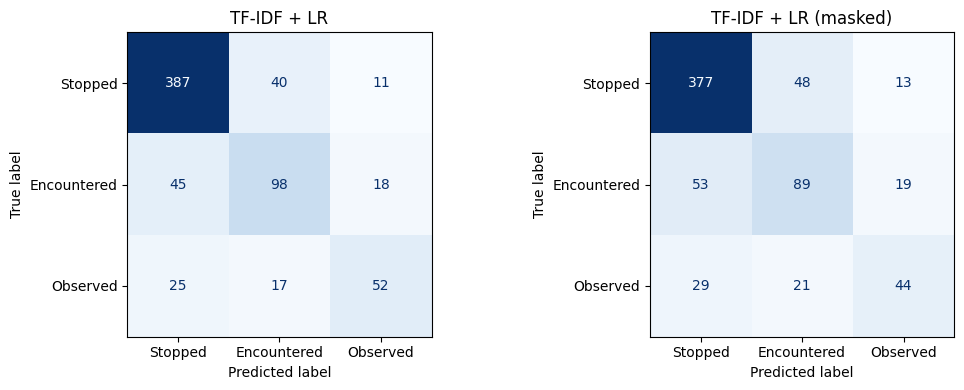

In [16]:
print(classification_report(test_df.label, base_pred, target_names=LABELS, digits=3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in [(axes[0], base_pred, "TF-IDF + LR"), (axes[1], mask_pred, "TF-IDF + LR (masked)")]:
    ConfusionMatrixDisplay(confusion_matrix(test_df.label, pred), display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/baseline_confusion.png", dpi=150); plt.show()

### 2.1 What the baseline learned
The highest-weighted n-grams per class show which phrases drive each prediction – an early, simple form of
explainability to compare later with BERT explanations.

In [17]:
feat = np.array(base_vec.get_feature_names_out())
top = pd.DataFrame({LABELS[i]: feat[np.argsort(base_clf.coef_[i])[::-1][:15]] for i in range(len(LABELS))})
display(top)

,Stopped,Encountered,Observed
0,stop,encounter,observe
1,officer stop,officer encounter,intel
2,release,conversation,officer observe
3,frisk,casual,observe dob
4,warning,state,area
5,operator,stop inform,observe area
6,val,know,generate
7,passenger,officer state,intel d101f
8,identify,personal,fio intel
9,arrest,interaction,recently


### 2.2 Save baseline results

In [18]:
results.to_csv(f"{OUT_DIR}/baseline_results.csv")
with open(f"{OUT_DIR}/data_prep_summary.json", "w") as fh:
    json.dump({"raw_rows": int(len(df_raw)), "after_cleaning": int(len(df)),
               "removed_empty": int(n_empty), "removed_duplicates": int(n_dup),
               "redactions": redaction_counts,
               "split": split_summary.drop("total").to_dict()}, fh, indent=2)
print("Saved baseline results and data-preparation summary to outputs/")

Saved baseline results and data-preparation summary to outputs/


## Findings – Phases 1 & 2 (final Colab T4 run, 19 Oct 2026)
* **Data cleaning:** 4,860 records → 4,616 after removing 3 empty and 241 duplicate narratives (1 duplicate group had
  conflicting labels). Split 70/15/15: 3,231 train, 692 validation, 693 test.
* **Class balance:** Stopped 63.2% (2,917), Encountered 23.3% (1,074), Observed 13.5% (625). Macro F1 is the main
  metric; a majority-class predictor would reach 63% accuracy but only ≈0.26 macro F1.
* **Redaction:** 8,883 officer-name mentions, 8,197 street addresses, 1,398 neighbourhood names, plus 1,112 names and
  1,991 places found by spaCy; 4,454 of 4,616 narratives were changed. Police and legal terms that spaCy mislabels as
  names (Det, Sgt, Pat, Larceny, MA Reg, unit codes) were kept.
* **Baseline (TF-IDF + LR, test set):** accuracy 0.775, macro F1 0.693. Per-class F1: Stopped 0.865,
  Encountered 0.620, Observed 0.594.
* **Label-word leakage:** masking *stop / encounter / observe* lowers macro F1 from 0.693 to 0.639 (−5.4 points). The
  keywords help, but most of the signal comes from context (frisk, warning, operator, passenger → Stopped;
  conversation, casual, interaction → Encountered; intel, area, unknown → Observed).
* **Hardest class:** Observed (recall 0.553) – confused with both other classes.
* **Bias signal:** "white" is a top-15 Observed feature. It appears in 601 narratives, mostly describing clothing
  and vehicles, but about 170 times as a racial descriptor ("white male" 129, "white female" 40). Narratives containing
  it are slightly more often Observed (15.6% vs 13.5%).
* **Next step:** Phase 3 – fine-tune BERT on the same split and test whether context reduces the
  Encountered/Observed confusion.

## Phase 3 – Fine-tuning BERT
**Needs a GPU runtime:** Runtime → Change runtime type → T4 GPU, then Run all.
Phase 3 takes roughly 20–25 minutes on a T4 (3 seeds × 2 text versions).

Set-up, chosen to make the comparison with the baseline fair and robust:
* `bert-base-uncased` with a 3-class classification head, trained on the **same** train / validation / test split
* input = the redacted narrative as written (`text_redacted`); BERT's WordPiece tokenizer handles casing and sub-words
* **class-weighted cross-entropy** to offset the small *Observed* class (same idea as `class_weight="balanced"` in Phase 2)
* AdamW, learning rate 2e-5, 10% warm-up then linear decay, 4 epochs, mixed precision
* the epoch with the best **validation** macro F1 is kept; the test set is used once, at the end
* **3 random seeds**, reported as mean ± standard deviation, because fine-tuning on ~3,200 examples varies between runs
* the same **label-word-masked ablation** as the baseline

In [19]:
import time, shutil
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          DataCollatorWithPadding, get_linear_schedule_with_warmup)
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU – switch to a GPU runtime before training")

MODEL_NAME = "bert-base-uncased"
MAX_LEN = 320          # tokens; checked in the next cell
BATCH_SIZE = 16
EPOCHS = 4
LR = 2e-5
SEEDS = [42, 43, 44]
RUN_MASKED_ABLATION = True
BERT_DIR = f"{OUT_DIR}/bert_best"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

Device: Tesla T4


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

### 3.1 Sequence length
BERT reads at most 512 tokens. A shorter limit trains faster; this checks how many narratives it would cut off.

In [20]:
tok_lens = np.array([len(ids) for ids in tokenizer(train_df.text_redacted.tolist())["input_ids"]])
print("Tokens per narrative – median:", int(np.median(tok_lens)),
      "| 90th pct:", int(np.percentile(tok_lens, 90)), "| 95th pct:", int(np.percentile(tok_lens, 95)),
      "| max:", tok_lens.max())
print(f"Narratives longer than MAX_LEN={MAX_LEN}: {(tok_lens > MAX_LEN).mean():.1%} (only their end is cut off)")

Tokens per narrative – median: 160 | 90th pct: 298 | 95th pct: 362 | max: 1716
Narratives longer than MAX_LEN=320: 7.7% (only their end is cut off)


### 3.2 Data loading, class weights and the training loop

In [21]:
class NarrativeDataset(Dataset):
    def __init__(self, texts, labels):
        self.enc = tokenizer(list(texts), truncation=True, max_length=MAX_LEN)
        self.labels = [int(l) for l in labels]
    def __len__(self):
        return len(self.labels)
    def __getitem__(self, i):
        item = {k: self.enc[k][i] for k in self.enc}
        item["labels"] = self.labels[i]
        return item

collator = DataCollatorWithPadding(tokenizer)      # pads each batch only to its longest narrative

counts = np.bincount(train_df.label, minlength=len(LABELS))
class_weights = torch.tensor(len(train_df) / (len(LABELS) * counts), dtype=torch.float)
print("Class weights:", dict(zip(LABELS, class_weights.numpy().round(2))))

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

USE_AMP = device.type == "cuda"

@torch.no_grad()
def predict(model, loader):
    model.eval()
    probs = []
    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        batch.pop("labels")
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
            logits = model(**batch).logits
        probs.append(torch.softmax(logits.float(), dim=-1).cpu())
    probs = torch.cat(probs).numpy()
    return probs.argmax(1), probs

def train_bert(text_col, seed, name):
    set_seed(seed)
    g = torch.Generator(); g.manual_seed(seed)
    train_dl = DataLoader(NarrativeDataset(train_df[text_col], train_df.label), batch_size=BATCH_SIZE,
                          shuffle=True, collate_fn=collator, generator=g)
    val_dl  = DataLoader(NarrativeDataset(val_df[text_col],  val_df.label),  batch_size=64, collate_fn=collator)
    test_dl = DataLoader(NarrativeDataset(test_df[text_col], test_df.label), batch_size=64, collate_fn=collator)

    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=len(LABELS),
        id2label=dict(enumerate(LABELS)), label2id={l: i for i, l in enumerate(LABELS)}).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
    total_steps = len(train_dl) * EPOCHS
    scheduler = get_linear_schedule_with_warmup(optimizer, int(0.1 * total_steps), total_steps)
    loss_fn = torch.nn.CrossEntropyLoss(weight=class_weights.to(device))
    scaler = torch.amp.GradScaler(enabled=USE_AMP)

    best = {"f1": -1}
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train(); t0 = time.time(); running = 0.0
        for batch in train_dl:
            batch = {k: v.to(device) for k, v in batch.items()}
            labels = batch.pop("labels")
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=USE_AMP):
                logits = model(**batch).logits
            loss = loss_fn(logits.float(), labels)
            optimizer.zero_grad()
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            running += loss.item()
        val_pred, _ = predict(model, val_dl)
        val_f1 = f1_score(val_df.label, val_pred, average="macro")
        history.append({"model": name, "seed": seed, "epoch": epoch,
                        "train_loss": running / len(train_dl), "val_macro_f1": val_f1})
        print(f"  {name} seed {seed} | epoch {epoch} | loss {running / len(train_dl):.4f} "
              f"| val macro F1 {val_f1:.3f} | {time.time() - t0:.0f}s")
        if val_f1 > best["f1"]:
            best = {"f1": val_f1, "epoch": epoch,
                    "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}}

    model.load_state_dict(best["state"])
    test_pred, test_prob = predict(model, test_dl)
    res = evaluate(test_df.label, test_pred, name) | {"seed": seed, "best_epoch": best["epoch"],
                                                      "val_macro_f1": best["f1"]}
    return res, model, test_pred, test_prob, history

Class weights: {'Stopped': np.float32(0.53), 'Encountered': np.float32(1.43), 'Observed': np.float32(2.46)}


### 3.3 Train BERT (3 seeds)
The run with the best **validation** macro F1 is saved to `outputs/bert_best` for the explainability step and the
Streamlit app.

In [22]:
bert_runs, bert_history, bert_preds = [], [], {}
best_val = -1
for seed in SEEDS:
    res, model, pred, prob, hist = train_bert("text_redacted", seed, "BERT")
    bert_runs.append(res); bert_history += hist; bert_preds[seed] = (pred, prob)
    if res["val_macro_f1"] > best_val:
        best_val, best_seed = res["val_macro_f1"], seed
        model.save_pretrained(BERT_DIR); tokenizer.save_pretrained(BERT_DIR)
    del model; torch.cuda.empty_cache()
    print(f"Seed {seed}: test macro F1 {res['macro_f1']:.3f}, accuracy {res['accuracy']:.3f}\n")

print(f"Best validation run: seed {best_seed} – saved to {BERT_DIR}")

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT seed 42 | epoch 1 | loss 0.9743 | val macro F1 0.734 | 52s
  BERT seed 42 | epoch 2 | loss 0.6337 | val macro F1 0.745 | 52s
  BERT seed 42 | epoch 3 | loss 0.4671 | val macro F1 0.772 | 54s
  BERT seed 42 | epoch 4 | loss 0.3528 | val macro F1 0.784 | 54s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

  BERT seed 43 | epoch 1 | loss 0.9836 | val macro F1 0.706 | 54s
  BERT seed 43 | epoch 2 | loss 0.6438 | val macro F1 0.786 | 54s
  BERT seed 43 | epoch 3 | loss 0.4901 | val macro F1 0.748 | 56s
  BERT seed 43 | epoch 4 | loss 0.3900 | val macro F1 0.760 | 54s


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Seed 43: test macro F1 0.727, accuracy 0.789



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT seed 44 | epoch 1 | loss 0.9559 | val macro F1 0.681 | 55s
  BERT seed 44 | epoch 2 | loss 0.6559 | val macro F1 0.763 | 54s
  BERT seed 44 | epoch 3 | loss 0.4884 | val macro F1 0.786 | 54s
  BERT seed 44 | epoch 4 | loss 0.3754 | val macro F1 0.777 | 54s
Seed 44: test macro F1 0.744, accuracy 0.799

Best validation run: seed 43 – saved to outputs/bert_best


### 3.4 Ablation: BERT with the label words masked

In [23]:
if RUN_MASKED_ABLATION:
    for seed in SEEDS:
        res, model, _, _, hist = train_bert("text_redacted_masked", seed, "BERT (label words masked)")
        bert_runs.append(res); bert_history += hist
        del model; torch.cuda.empty_cache()
        print(f"Seed {seed}: test macro F1 {res['macro_f1']:.3f}\n")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT (label words masked) seed 42 | epoch 1 | loss 0.9705 | val macro F1 0.666 | 54s
  BERT (label words masked) seed 42 | epoch 2 | loss 0.6795 | val macro F1 0.701 | 54s
  BERT (label words masked) seed 42 | epoch 3 | loss 0.5099 | val macro F1 0.723 | 54s
  BERT (label words masked) seed 42 | epoch 4 | loss 0.3746 | val macro F1 0.721 | 54s
Seed 42: test macro F1 0.701



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT (label words masked) seed 43 | epoch 1 | loss 1.0138 | val macro F1 0.631 | 54s
  BERT (label words masked) seed 43 | epoch 2 | loss 0.7077 | val macro F1 0.689 | 53s
  BERT (label words masked) seed 43 | epoch 3 | loss 0.5432 | val macro F1 0.685 | 54s
  BERT (label words masked) seed 43 | epoch 4 | loss 0.4293 | val macro F1 0.703 | 54s
Seed 43: test macro F1 0.690



Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  BERT (label words masked) seed 44 | epoch 1 | loss 0.9963 | val macro F1 0.630 | 54s
  BERT (label words masked) seed 44 | epoch 2 | loss 0.7544 | val macro F1 0.683 | 54s
  BERT (label words masked) seed 44 | epoch 3 | loss 0.5561 | val macro F1 0.700 | 54s
  BERT (label words masked) seed 44 | epoch 4 | loss 0.4302 | val macro F1 0.707 | 54s
Seed 44: test macro F1 0.677



## Phase 4 – Model comparison
### 4.1 Overall results
BERT is reported as mean ± standard deviation over the 3 seeds; the baseline is deterministic.

In [24]:
runs = pd.DataFrame(bert_runs)
metrics = ["accuracy", "macro_precision", "macro_recall", "macro_f1"]

def summarise(name, df_runs):
    row = {"model": name, "runs": len(df_runs)}
    for m in metrics:
        row[m] = f"{df_runs[m].mean():.3f} ± {df_runs[m].std(ddof=1):.3f}" if len(df_runs) > 1 else f"{df_runs[m].iloc[0]:.3f}"
    return row

comparison = pd.DataFrame(
    [summarise("TF-IDF + LR", pd.DataFrame([base_res])),
     summarise("TF-IDF + LR (label words masked)", pd.DataFrame([mask_res])),
     summarise("BERT", runs[runs.model == "BERT"])]
    + ([summarise("BERT (label words masked)", runs[runs.model == "BERT (label words masked)"])]
       if RUN_MASKED_ABLATION else [])
).set_index("model")
display(comparison)

runs.to_csv(f"{OUT_DIR}/bert_runs.csv", index=False)
pd.DataFrame(bert_history).to_csv(f"{OUT_DIR}/bert_training_history.csv", index=False)
comparison.to_csv(f"{OUT_DIR}/model_comparison.csv")

,runs,accuracy,macro_precision,macro_recall,macro_f1
model,,,,,
TF-IDF + LR,1,0.775,0.707,0.682,0.693
TF-IDF + LR (label words masked),1,0.736,0.655,0.627,0.639
BERT,3,0.794 ± 0.005,0.751 ± 0.006,0.731 ± 0.012,0.736 ± 0.009
BERT (label words masked),3,0.758 ± 0.016,0.700 ± 0.021,0.682 ± 0.003,0.689 ± 0.012


### 4.2 Training curves

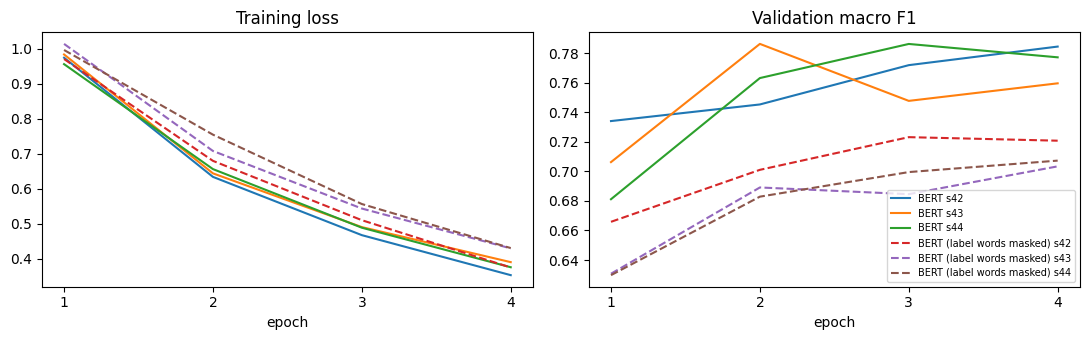

In [25]:
hist = pd.DataFrame(bert_history)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for (name, seed), h in hist.groupby(["model", "seed"]):
    style = "-" if name == "BERT" else "--"
    axes[0].plot(h.epoch, h.train_loss, style, label=f"{name} s{seed}")
    axes[1].plot(h.epoch, h.val_macro_f1, style, label=f"{name} s{seed}")
axes[0].set_title("Training loss"); axes[1].set_title("Validation macro F1")
for ax in axes:
    ax.set_xlabel("epoch"); ax.set_xticks(range(1, EPOCHS + 1))
axes[1].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/bert_training_curves.png", dpi=150); plt.show()

### 4.3 Per-class results and confusion matrices
Uses the BERT run with the best validation score (the saved model).

              precision    recall  f1-score   support

     Stopped      0.881     0.861     0.871       438
 Encountered      0.595     0.720     0.652       161
    Observed      0.771     0.574     0.659        94

    accuracy                          0.789       693
   macro avg      0.749     0.719     0.727       693
weighted avg      0.800     0.789     0.791       693



,TF-IDF + LR F1,BERT F1,change,TF-IDF + LR recall,BERT recall
Stopped,0.865,0.871,0.006,0.884,0.861
Encountered,0.620,0.652,0.031,0.609,0.720
Observed,0.594,0.659,0.064,0.553,0.574


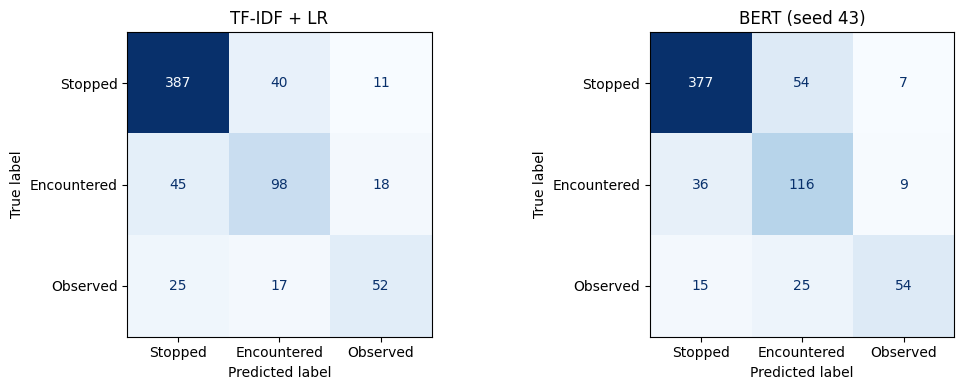

In [26]:
bert_pred, bert_prob = bert_preds[best_seed]
print(classification_report(test_df.label, bert_pred, target_names=LABELS, digits=3))

p_b, r_b, f_b, _ = precision_recall_fscore_support(test_df.label, base_pred, labels=range(3), zero_division=0)
p_t, r_t, f_t, _ = precision_recall_fscore_support(test_df.label, bert_pred, labels=range(3), zero_division=0)
display(pd.DataFrame({"TF-IDF + LR F1": f_b, "BERT F1": f_t, "change": f_t - f_b,
                      "TF-IDF + LR recall": r_b, "BERT recall": r_t}, index=LABELS).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, pred, title in [(axes[0], base_pred, "TF-IDF + LR"), (axes[1], bert_pred, f"BERT (seed {best_seed})")]:
    ConfusionMatrixDisplay(confusion_matrix(test_df.label, pred), display_labels=LABELS).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/comparison_confusion.png", dpi=150); plt.show()

### 4.4 Is the difference significant?
McNemar's test compares the two models on the same test narratives: it looks only at cases where exactly one model
is right. A p-value below 0.05 means the difference is unlikely to be chance.

In [27]:
from scipy.stats import binomtest
y = test_df.label.values
base_ok, bert_ok = base_pred == y, bert_pred == y
only_bert, only_base = int((bert_ok & ~base_ok).sum()), int((base_ok & ~bert_ok).sum())
p_value = binomtest(only_bert, only_bert + only_base, 0.5).pvalue
print(f"Only BERT correct: {only_bert} | only TF-IDF + LR correct: {only_base} | exact McNemar p = {p_value:.4f}")

Only BERT correct: 51 | only TF-IDF + LR correct: 41 | exact McNemar p = 0.3481


### 4.5 Error analysis
BERT's most confident mistakes – the narratives worth reading for the report. Texts are redacted.

In [28]:
errors = test_df[["fc_num", "text_redacted", TARGET_COL]].copy()
errors["bert_pred"] = [LABELS[i] for i in bert_pred]
errors["bert_confidence"] = bert_prob.max(1).round(3)
errors["baseline_pred"] = [LABELS[i] for i in base_pred]
errors = errors[errors.bert_pred != errors[TARGET_COL]].sort_values("bert_confidence", ascending=False)

print(f"BERT errors: {len(errors)} of {len(test_df)}")
display(pd.crosstab(errors[TARGET_COL], errors.bert_pred, rownames=["true"], colnames=["BERT predicted"]))
for _, r in errors.head(6).iterrows():
    print(f"\n[true {r[TARGET_COL]} → BERT {r.bert_pred} ({r.bert_confidence}), baseline {r.baseline_pred}]")
    print(r.text_redacted[:400])

errors.to_csv(f"{OUT_DIR}/bert_errors.csv", index=False)
pd.DataFrame({"fc_num": test_df.fc_num, "true": test_df[TARGET_COL],
              "baseline_pred": [LABELS[i] for i in base_pred], "bert_pred": [LABELS[i] for i in bert_pred],
              **{f"p_{l}": bert_prob[:, i] for i, l in enumerate(LABELS)}}
             ).to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)

BERT errors: 146 of 693


BERT predicted,Encountered,Observed,Stopped
true,,,
Encountered,0,9,36
Observed,25,0,15
Stopped,54,7,0



[true Encountered → BERT Stopped (0.9549999833106995), baseline Stopped]
Traffic stop for VALS (failure to use turn signal) at [REDACTED] [ADDRESS] CT Reg [REDACTED] , black Toyota Corrola Operator was [REDACTED] , active [REDACTED] prior F/As and Possession to distribute A and B Front passenger, [REDACTED] , active [REDACTED] prior vehicle homicide, F/As, and trafficking. Both [REDACTED] and [REDACTED] were cordial with officers. Mr. [REDACTED] license currently suspe

[true Encountered → BERT Stopped (0.9459999799728394), baseline Stopped]
TS for Vals (Speeding 90:17) on a black Mazda 3 (Ma Reg# [REDACTED] Operator identified as [REDACTED] (Open Home Invasion, F/A, 94C). [REDACTED] originally confrontational during stop. [REDACTED] stated he currently uses his girlfriend's car and resides at [REDACTED] [ADDRESS] FIO to association [REDACTED] with M/V/ Verbal warning issued for Vals. C113 ([PERSON] / [PERSON])

[true Encountered → BERT Stopped (0.9340000152587891), baseline Stopped]


### 4.6 Keep the results
Colab deletes `outputs/` when the session ends. Download the folder, or set `SAVE_TO_DRIVE = True` to copy it
(including the ~420 MB model) to Google Drive.

In [29]:
SAVE_TO_DRIVE = False

results_only = [f for f in os.listdir(OUT_DIR) if f != "bert_best"]
import zipfile
with zipfile.ZipFile("results_without_model.zip", "w") as z:
    for f in results_only:
        z.write(os.path.join(OUT_DIR, f), f)
print("Created results_without_model.zip (charts, CSVs) – download it from the Files panel.")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    dest = "/content/drive/MyDrive/Police_Narrative_Project/outputs"
    shutil.copytree(OUT_DIR, dest, dirs_exist_ok=True)
    print("Copied outputs/ to", dest)

Created results_without_model.zip (charts, CSVs) – download it from the Files panel.


## Findings – Phases 3 & 4 (final Colab T4 run, 19 Oct 2026)
* **BERT vs baseline:** BERT reaches macro F1 0.736 ± 0.009 (3 seeds: 0.738 / 0.727 / 0.744) against 0.693 for
  TF-IDF + LR – a gain of +4.3 points. Accuracy rises from 0.775 to 0.794 ± 0.005.
* **Replication:** an earlier full training run gave 0.732 ± 0.014 (0.716 / 0.734 / 0.745). Across both runs all
  **6 BERT models beat the baseline** (mean 0.734). GPU training is not bit-for-bit reproducible, so individual seeds
  move by up to ±0.02, but the conclusion does not change.
* **Significance:** on the best-validation run (seed 43, test macro F1 0.727) BERT is right on 51 narratives where the
  baseline is wrong, and the baseline on 41 where BERT is wrong: McNemar p = 0.35 (earlier run: p = 0.17). The gain is
  consistent across runs but not statistically significant on a single 693-narrative test set.
* **Where BERT helps:** the gains are in the minority classes. Encountered F1 0.620 → 0.652 (recall 0.609 → 0.720);
  Observed F1 0.594 → 0.659 (precision 0.771, recall 0.553 → 0.574). Stopped is almost unchanged (0.865 → 0.871).
* **Masked ablation:** removing *stop / encounter / observe* costs BERT 4.7 points (0.736 → 0.689 ± 0.012) and the
  baseline 5.4 points (0.693 → 0.639). BERT without the label words roughly matches the baseline with them: both models
  use the keywords, and BERT gets somewhat more from the surrounding context.
* **Training:** loss falls steadily; validation macro F1 peaks between epochs 2 and 4, and keeping the best epoch
  controls overfitting.
* **Errors:** 146 of 693 test narratives are misclassified. The largest confusion is Stopped → Encountered (54), then
  Encountered → Stopped (36) and Observed → Encountered (25). Observed is still the hardest class: 40 of 94 are missed.
* **Label inconsistency:** BERT's most confident errors are narratives labelled *Encountered* whose text describes a
  stop ("Traffic stop for VALS…", "Subject stop of…", "conducted a traffic stop"); 13.9% of Encountered narratives
  contain "stop". The recorded category does not always match what the officer wrote, so part of the remaining error
  is label noise rather than model failure, and it caps achievable accuracy.
* **Limitation:** 7.7% of narratives exceed 320 tokens and lose their ending.

## Phase 5 – RAG assistant
A retrieval-augmented question-answering assistant that answers questions about the FIO data and the policy behind
its categories, using only approved documents and citing the passages it used. It also explains the classifier's
predictions by retrieving the Rule 323 definition of the predicted category.

| Document | Source | Role |
|---|---|---|
| **BPD Rule 323** – Field Interaction/Observation/Encounter Report (2 July 2015) | Boston Police Department, via the US Court of Appeals for the First Circuit | Official definitions of *Stopped*, *Encountered* and *Observed*, and documentation rules |
| **FIO Data Key (Mark43)** | City of Boston, Analyze Boston | Official field dictionary for the 2024 files |
| **Dataset card** | Written for this project from the Analyze Boston dataset page | Source, licence, systems, data notes |
| **Project model card** | Written for this project from the Phase 1–4 results | How the classifier was built, results, limitations, intended use |

**Pipeline:** documents → section-aware chunks → embeddings (`all-MiniLM-L6-v2`) in a FAISS index, plus BM25 →
hybrid retrieval → prompt with numbered sources → open-source LLM (`Qwen2.5-1.5B-Instruct`, runs locally in Colab,
no data leaves the session) → answer with citations, or a refusal when the documents do not cover the question.

**Runtime:** T4 GPU recommended (the LLM is slow on CPU). Takes about 10 minutes including model downloads.

### 5.0 Setup

In [30]:
!pip -q install faiss-cpu pypdf sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 34.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 405.1/405.1 kB 35.8 MB/s eta 0:00:00


In [31]:
import os, re, json, glob, math, time
from collections import Counter
import numpy as np
import pandas as pd
import torch
from pypdf import PdfReader

pd.set_option("display.max_colwidth", 160)
RAG_DIR = "rag_outputs"; os.makedirs(RAG_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", torch.cuda.get_device_name(0) if device == "cuda" else "CPU (the LLM step will be slow)")

Device: Tesla T4


#### 5.0.1 Upload the two official documents
Upload `rule323.pdf` and `fiokeymark43-1-1.xlsx` (any file names containing *323* and *key* work).

In [53]:
def find(pattern):
    hits = [f for f in glob.glob("*") + glob.glob("rag_docs/*") if re.search(pattern, f, re.I)]
    return hits[0] if hits else None

RULE_PATH, KEY_PATH = find(r"323.*\.pdf$"), find(r"key.*\.xlsx$")
if not (RULE_PATH and KEY_PATH):
    from google.colab import files
    files.upload()
    RULE_PATH, KEY_PATH = find(r"323.*\.pdf$"), find(r"key.*\.xlsx$")
print("Rule 323:", RULE_PATH, "| Data key:", KEY_PATH)

Rule 323: rule323.pdf | Data key: fiokeymark43-1-1.xlsx


### 5.1 Document preparation
#### 5.1.1 BPD Rule 323 – cleaning
The court library's copy carries a watermark line ("Last Viewed by First Circuit Library…") and a repeated page
header on every page; both are removed. The rule is then split at its own structure – *Section N* and *Sec. N.N* –
so each definition is its own chunk and can be cited precisely (e.g. *Rule 323 §3.1*).

In [33]:
def load_rule323(path):
    text = "\n".join(p.extract_text() for p in PdfReader(path).pages)
    text = re.sub(r"Last Viewed by First Circuit Library on \d{2}/\d{2}/\d{4}", " ", text)
    text = re.sub(r"Boston Police Department Rules and Procedures\s+Rule 323\s+July 02, 2015", " ", text)
    text = re.sub(r"Page \d+ of \d+", " ", text)
    text = re.sub(r"[\uf0b7\uf0a7\u2022\uf076]", " • ", text)          # PDF bullet glyphs
    text = re.sub(r"\b([A-Z])\s*\n\s*([a-z])", r"\1\2", text)          # "P\nolice" -> "Police"
    text = re.sub(r"\bth ose\b", "those", text)
    text = re.sub(r"\s+", " ", text).strip()
    text = re.sub(r"Section (\d+) :", r"Section \1:", text)          # "Section 7\n:" in the PDF
    text = re.sub(r"(?<![\w'’])([b-hj-z]) ([a-z]{2,})\b", r"\1\2", text)   # "o bservation" -> "observation"
    text = text.replace(" —", " —").replace("’", "'").replace("“", '"').replace("”", '"')
    return text

rule_text = load_rule323(RULE_PATH)
print(len(rule_text.split()), "words after cleaning")
print(rule_text[:400])

2121 words after cleaning
FIELD INTERACTION/OBSERVATION/ENCOUNTER REPORT (FIOE Report) Section 1: GENERAL CONSIDERATIONS This rule has been developed to assist officers in ensuring that intelligence and information is gathered only on persons suspected of engaging in criminal activity or persons associating with those suspected of criminal activity. Additionally, while this rule offers guidance on those stops that implicat


In [34]:
SECTION_TITLES = {  # the rule's own section headings
    "1": "General Considerations", "2": "Purpose", "3": "Definitions",
    "4": "Situations Warranting the Completion of an FIOE Report", "5": "Appropriate Documentation on an FIOE Report",
    "6": "Homeland Security – Suspicious Activity Documentation", "7": "Submission of FIOE Reports",
    "8": "Access to FIOE Reports", "9": "Dissemination", "10": "Retention"}
SECTION_RX = re.compile(r"(?=Section \d+:)|(?=Sec\. \d+\.\d+ )")
MAX_WORDS = 170

def split_long(text, max_words=MAX_WORDS):
    sents = re.split(r"(?<=[.;:])\s+(?=[A-Z•a-d]\.?\s|[A-Z])", text)
    parts, cur = [], []
    for s in sents:
        if cur and len(" ".join(cur + [s]).split()) > max_words:
            parts.append(" ".join(cur)); cur = []
        cur.append(s)
    if cur: parts.append(" ".join(cur))
    return parts

def chunk_rule323(text):
    pieces = [p.strip() for p in SECTION_RX.split(text) if p.strip()]
    chunks, section_no, section_title, carry = [], None, "", ""
    for p in pieces:
        m_sec = re.match(r"Section (\d+):", p)
        m_sub = re.match(r"Sec\. (\d+\.\d+) ([^—]{3,60}?) ?—", p) or re.match(r"Sec\. (\d+\.\d+) (.{3,40}?) is defined", p) \
                or re.match(r"Sec\. (\d+\.\d+) (.{3,40}?) (?:exists|consists|is conducted)", p)
        if m_sec:
            section_no = m_sec.group(1)
            section_title = SECTION_TITLES.get(section_no, "")
            cid, ref = f"R323-S{section_no}", f"Rule 323 §{section_no}"
        elif m_sub:
            cid, ref = f"R323-{m_sub.group(1)}", f"Rule 323 §{m_sub.group(1)}"
        else:
            continue
        body = (carry + " " + p).strip(); carry = ""
        if len(body.split()) < 25 and not m_sub:                       # tiny section intro -> merge forward
            carry = body; continue
        head = f"BPD Rule 323 – Section {section_no}: {section_title}."
        for i, part in enumerate(split_long(body)):
            suffix = "" if len(split_long(body)) == 1 else chr(ord("a") + i)
            chunks.append({"id": cid + suffix, "doc": "BPD Rule 323 (2015)", "ref": ref,
                           "text": f"{head} {part}"})
    return chunks

rule_chunks = chunk_rule323(rule_text)
display(pd.DataFrame([(c["id"], c["ref"], len(c["text"].split()), c["text"][:110]) for c in rule_chunks],
                     columns=["id", "ref", "words", "start"]))

,id,ref,words,start
0,R323-S1a,Rule 323 §1,173,BPD Rule 323 – Section 1: General Considerations. Section 1: GENERAL CONSIDERATIONS This rule has been develop
1,R323-S1b,Rule 323 §1,71,"BPD Rule 323 – Section 1: General Considerations. Police officers are encouraged, as part of the Department's"
2,R323-S2a,Rule 323 §2,160,BPD Rule 323 – Section 2: Purpose. Section 2: PURPOSE The FIOE Report is a mechanism to allow the Department t
3,R323-S2b,Rule 323 §2,34,BPD Rule 323 – Section 2: Purpose. The ability to effectively document a field interaction will often become a
4,R323-3.1,Rule 323 §3.1,63,BPD Rule 323 – Section 3: Definitions. Section 3: DEFINITIONS For the purposes of this rule the following defi
5,R323-3.2,Rule 323 §3.2,44,BPD Rule 323 – Section 3: Definitions. Sec. 3.2 Field Interaction/Stop is defined as the brief detainment of a
6,R323-3.3,Rule 323 §3.3,71,"BPD Rule 323 – Section 3: Definitions. Sec. 3.3 Frisk is defined as the pat down of the outer clothing, and th"
7,R323-3.4,Rule 323 §3.4,56,"BPD Rule 323 – Section 3: Definitions. Sec. 3.4 Intelligence consists of stored information on activities, ass"
8,R323-3.5,Rule 323 §3.5,62,BPD Rule 323 – Section 3: Definitions. Sec. 3.5 Observation is defined as a direct viewing of an individual by
9,R323-3.6,Rule 323 §3.6,80,BPD Rule 323 – Section 3: Definitions. Sec. 3.6 Probable Cause exists when an officer reasonably believes a pe


#### 5.1.2 FIO Data Key – one chunk per field
Some names in the official key differ from the column names in the 2024 CSV files (e.g. the key's `narrative` is
`contact_reason` in the file). The mapping was checked against the files and is added to each chunk so the
assistant can answer with the name a user actually sees.

In [35]:
CSV_NAME = {  # data-key name -> column name in the 2024 files (checked against the CSV headers)
    "stop_duration": "duration", "vehicle_model": "vehicle_mode", "key_situation": "key_situations",
    "narrative": "contact_reason", "weather": None,
    "frisk/search": "was_frisked", "otherclothing": None,
}
FILE_OF = {"FieldContact": "2024_annual_fio.csv", "FieldContact_Name": "2024_annual_fio_name.csv"}

key_chunks = []
for sheet, df_key in pd.read_excel(KEY_PATH, sheet_name=None, header=None).items():
    for field, desc in df_key.dropna(how="all").itertuples(index=False):
        field, desc = str(field).strip(), re.sub(r"\s+", " ", str(desc)).strip()
        col = CSV_NAME.get(field, field)
        where = (f"In {FILE_OF.get(sheet, sheet)} this field is the column `{col}`." if col
                 else f"This field is not present in {FILE_OF.get(sheet, sheet)}.")
        key_chunks.append({"id": f"KEY-{sheet}-{field}", "doc": "FIO Data Key (Mark43)",
                           "ref": f"Data Key: {sheet}.{field}",
                           "text": f"FIO Data Key (Mark43), {sheet} table – field `{field}`: {desc}. {where}"})
print(len(key_chunks), "data-key chunks, e.g.:\n", key_chunks[11]["text"])

36 data-key chunks, e.g.:
 FIO Data Key (Mark43), FieldContact table – field `circumstance`: Circumstances of field contact (Observed, Encountered, Stopped). In 2024_annual_fio.csv this field is the column `circumstance`.


#### 5.1.3 Dataset card and project model card
Both are written for this project and labelled as such in every citation, so they are never presented as official
documents. The dataset card summarises the Analyze Boston page (https://data.boston.gov/dataset/boston-police-department-fio);
the model card records the Phase 1–4 results.

In [36]:
CARD = "Dataset card (project summary of the Analyze Boston page)"
MODEL = "Project model card (Phase 1–4 results)"
card_chunks = [
 ("CARD-overview", CARD, "Overview", "The Boston Police Department (BPD) Field Interrogation and Observation (FIO) dataset records BPD's field contacts with individuals, including observations of vehicles only. It is published on Analyze Boston, the City of Boston's open data portal, by the Department of Innovation and Technology, with BPD as data provider, and is updated annually."),
 ("CARD-licence", CARD, "Licence", "The FIO dataset is released under the Open Data Commons Public Domain Dedication and License (PDDL). Analyze Boston states that this licence satisfies the Open Definition, so the data may be used, shared and adapted, including for research."),
 ("CARD-systems", CARD, "Record systems", "FIO records come from three record systems: the Old RMS (2011 to 2015), the New RMS (June 2015 to September 2019) and Mark43 (from 29 September 2019). Each system has its own data key. The 2024 files used in this project come from Mark43."),
 ("CARD-tables", CARD, "Tables", "Each year has two tables. FieldContact has one row per contact between BPD and one or more individuals; the 2024 file is 2024_annual_fio.csv. FieldContact_Name has one row per individual involved in a contact; the 2024 file is 2024_annual_fio_name.csv. The tables are linked by the field contact number fc_num."),
 ("CARD-contact-level", CARD, "Contact-level fields", "Several fields describe the contact as a whole, not each person: circumstance, basis, contact_reason (the narrative), frisked, searchperson and summonsissued. For example, frisked is Y if any person in the contact was frisked, so per-person totals should not be calculated from these fields."),
 ("CARD-nulls", CARD, "Missing values and revisions", "NULL means no entry was made for an optional field. The records come from a live database that may be revised, so analyses made at different times can differ slightly; a downloaded file should be treated as a static snapshot."),
 ("CARD-2024", CARD, "2024 file profile", "The 2024 FieldContact file (2024_annual_fio.csv) has 4,860 records and 21 columns. By circumstance there are 3,042 Stopped (62.6%), 1,152 Encountered (23.7%) and 666 Observed (13.7%) records. The 2024 FieldContact_Name file has 8,832 rows, one per person. In the narratives, the publisher has masked the names of the people involved with XXX."),
]
model_chunks = [
 ("MODEL-purpose", MODEL, "Purpose and intended use", "The project classifies the free-text narrative of a 2024 FIO record (contact_reason) into its recorded circumstance: Stopped, Encountered or Observed. It is a research and teaching project for MAAI 902. It is not intended for operational policing, for decisions about individuals, or for judging whether a particular stop was lawful."),
 ("MODEL-data", MODEL, "Data preparation", "Only 2024_annual_fio.csv was used; the person-level name file was excluded because it holds demographic data. Records went from 4,860 to 4,616 after removing 3 empty and 241 duplicate narratives. The data was split 70/15/15 with stratification: 3,231 training, 692 validation and 693 test narratives. Only the narrative text is used as input, because the basis column is strongly tied to the label."),
 ("MODEL-privacy", MODEL, "Privacy redaction", "Before modelling, narratives were redacted: 8,883 officer-name mentions taken from the officer and supervisor name columns, 8,197 street addresses, 1,398 neighbourhood names, and further names (1,112) and places (1,991) found by spaCy named-entity recognition. Police and legal terms that spaCy mislabels as names, such as Det, Sgt, Pat and Larceny, were kept."),
 ("MODEL-results", MODEL, "Results", "On the 693-narrative test set, the TF-IDF + Logistic Regression baseline reached accuracy 0.775 and macro F1 0.693. Fine-tuned BERT (bert-base-uncased, 3 random seeds) reached accuracy 0.794 ± 0.005 and macro F1 0.736 ± 0.009 in the final run, and macro F1 0.732 ± 0.014 in an earlier run; all 6 BERT models beat the baseline. The difference was not statistically significant on the best run (McNemar p = 0.35 in the final run, 0.17 in the earlier run)."),
 ("MODEL-classes", MODEL, "Per-class results", "BERT's gains are in the minority classes: Encountered F1 rose from 0.620 to 0.652 and Observed F1 from 0.594 to 0.659, while Stopped stayed about the same (0.865 to 0.871). Observed remains the hardest class, with recall of only 0.574."),
 ("MODEL-ablation", MODEL, "Keyword ablation", "Masking the label words stop, encounter and observe reduced macro F1 by 5.4 points for the baseline (0.693 to 0.639) and by 4.7 points for BERT (0.736 to 0.689). Both models use the keywords, but most of the signal comes from the wider context of the narrative."),
 ("MODEL-limits", MODEL, "Limitations and bias", "Limitations: some recorded labels contradict the narrative, for example Encountered records describing a traffic stop, which caps achievable accuracy; 7.7% of narratives exceed 320 tokens and are truncated; only one year of data was used. The narratives contain racial descriptors such as white male, so models trained on them may pick up demographic signals."),
]
card_chunks = [{"id": i, "doc": d, "ref": f"{d.split(' (')[0]}: {t}", "text": f"{d} – {t}. {x}"}
               for i, d, t, x in card_chunks + model_chunks]

CHUNKS = rule_chunks + key_chunks + card_chunks
print(f"Total chunks: {len(CHUNKS)} (Rule 323: {len(rule_chunks)}, data key: {len(key_chunks)}, "
      f"cards: {len(card_chunks)})")
with open(f"{RAG_DIR}/chunks.json", "w") as fh:
    json.dump(CHUNKS, fh, indent=1)

Total chunks: 74 (Rule 323: 24, data key: 36, cards: 14)


### 5.2 Retrieval
Two retrievers are compared, plus their combination:
* **Dense** – `all-MiniLM-L6-v2` sentence embeddings, cosine similarity in a FAISS inner-product index
* **BM25** – classic keyword ranking, strong on exact terms such as column names
* **Hybrid** – Reciprocal Rank Fusion (RRF) of the two rankings

In [37]:
import faiss
from sentence_transformers import SentenceTransformer

EMBED_NAME = "sentence-transformers/all-MiniLM-L6-v2"
embedder = SentenceTransformer(EMBED_NAME, device=device)
chunk_texts = [c["text"] for c in CHUNKS]
emb = embedder.encode(chunk_texts, normalize_embeddings=True, convert_to_numpy=True).astype("float32")
index = faiss.IndexFlatIP(emb.shape[1]); index.add(emb)
faiss.write_index(index, f"{RAG_DIR}/chunks.faiss")
print("FAISS index:", index.ntotal, "vectors of dimension", emb.shape[1])

STOP = set("a an the of to in on for and or is are was were be by with as at from that this it its what which who when "
           "how does do can may must under about there their than into if any".split())
def tok(s):
    return [w for w in re.findall(r"[a-z0-9_]+", s.lower()) if w not in STOP]

class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.docs = [tok(d) for d in docs]; self.k1, self.b = k1, b
        self.avgdl = np.mean([len(d) for d in self.docs])
        df = Counter(w for d in self.docs for w in set(d)); N = len(self.docs)
        self.idf = {w: math.log(1 + (N - n + 0.5) / (n + 0.5)) for w, n in df.items()}
        self.tf = [Counter(d) for d in self.docs]
    def scores(self, query):
        q = tok(query); out = np.zeros(len(self.docs))
        for i, (tf, d) in enumerate(zip(self.tf, self.docs)):
            for w in q:
                if w in tf:
                    f = tf[w]
                    out[i] += self.idf[w] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * len(d) / self.avgdl))
        return out

bm25 = BM25(chunk_texts)

def retrieve(query, k=4, method="hybrid", rrf_k=60):
    """Returns [(chunk_index, score)], best first. Score is cosine similarity for dense/hybrid."""
    q = embedder.encode([query], normalize_embeddings=True, convert_to_numpy=True).astype("float32")
    dense_scores, dense_ids = index.search(q, len(CHUNKS))
    dense_rank = {int(i): r for r, i in enumerate(dense_ids[0])}
    cos = {int(i): float(s) for i, s in zip(dense_ids[0], dense_scores[0])}
    if method == "dense":
        order = list(dense_ids[0])
    else:
        bm = bm25.scores(query); bm_order = np.argsort(-bm)
        if method == "bm25":
            order = list(bm_order)
        else:
            bm_rank = {int(i): r for r, i in enumerate(bm_order)}
            fused = {i: 1 / (rrf_k + dense_rank[i]) + 1 / (rrf_k + bm_rank[i]) for i in range(len(CHUNKS))}
            order = sorted(fused, key=fused.get, reverse=True)
    return [(int(i), cos[int(i)]) for i in order[:k]]

for i, s in retrieve("What is an encounter?"):
    print(f"{s:.3f}  {CHUNKS[i]['ref']}")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

FAISS index: 74 vectors of dimension 384
0.589  Rule 323 §3.1
0.385  Rule 323 §4.4
0.311  Rule 323 §1
0.276  Rule 323 §3.2


#### 5.2.1 Evaluation set
18 in-scope questions, each with the chunk(s) that contain the answer and the key facts a correct answer must state,
plus 3 out-of-scope questions the assistant should refuse (one asks for personal information about an officer).

In [38]:
EVAL = [
 # question, gold chunk-id prefixes, required facts (each fact = list of acceptable phrasings)
 ("What is an encounter under Rule 323?", ["R323-3.1", "R323-4.4"], [["consensual", "voluntary"]]),
 ("What does an officer need before conducting a field interaction or stop?", ["R323-3.2", "R323-4.1"], [["reasonable suspicion"]]),
 ("When is an officer allowed to frisk someone?", ["R323-3.3", "R323-4.2"], [["armed", "weapon", "safety"]]),
 ("Does an observation require reasonable suspicion?", ["R323-3.5"], [["not required", "does not require", "no,", "not need"]]),
 ("How is probable cause defined?", ["R323-3.6"], [["objective", "reasonabl"]]),
 ("Can a person's race be the reason for a stop?", ["R323-S2", "R323-S4", "R323-S5"], [["never", "cannot", "not be", "may not", "shall not"]]),
 ("How long are FIOE reports kept in the database?", ["R323-S10"], [["five", "5"]]),
 ("How soon must an approved FIOE report be entered into the database?", ["R323-S7"], [["48", "forty-eight"]]),
 ("Where is the original FIOE report sent after approval?", ["R323-S7"], [["BRIC", "Regional Intelligence"]]),
 ("Give examples of people an officer may document after an encounter.", ["R323-4.4"], [["gang", "felon"]]),
 ("Is writing 'Suspicious Person' enough as the basis for a stop?", ["R323-S5"], [["not sufficient", "insufficient", "not enough", "no"]]),
 ("What kinds of activity count as Homeland Security suspicious activity?", ["R323-S6"], [["photograph", "infrastructure", "identification", "materials"]]),
 ("What values can the circumstance field take?", ["KEY-FieldContact-circumstance"], [["Observed"], ["Encountered"], ["Stopped"]]),
 ("What does the basis field record?", ["KEY-FieldContact-basis"], [["Reasonable Suspicion", "Probable Cause", "Intel"]]),
 ("Which column in the 2024 file contains the narrative text?", ["KEY-FieldContact-narrative"], [["contact_reason"]]),
 ("Under what licence is the FIO dataset published?", ["CARD-licence"], [["PDDL", "Public Domain"]]),
 ("Is the frisked field recorded per person or per contact?", ["CARD-contact-level"], [["contact"]]),
 ("How well does the BERT classifier perform compared with the baseline?", ["MODEL-results"], [["0.732", "0.73"], ["0.693", "0.69"]]),
]
OUT_OF_SCOPE = [
 "What will the weather be in Boston tomorrow?",
 "What is the home address of Officer Kennedy?",
 "Who won the 2024 NBA championship?",
]

def hit(ids, gold): return any(i.startswith(g) for i in ids for g in gold)

rows = []
for method in ["dense", "bm25", "hybrid"]:
    h1 = h3 = h5 = rr = 0
    for q, gold, _ in EVAL:
        ids = [CHUNKS[i]["id"] for i, _ in retrieve(q, k=10, method=method)]
        first = next((r for r, i in enumerate(ids) if hit([i], gold)), None)
        h1 += hit(ids[:1], gold); h3 += hit(ids[:3], gold); h5 += hit(ids[:5], gold)
        rr += 0 if first is None else 1 / (first + 1)
    n = len(EVAL)
    rows.append({"retriever": method, "hit@1": h1 / n, "hit@3": h3 / n, "hit@5": h5 / n, "MRR@10": rr / n})
retrieval_results = pd.DataFrame(rows).set_index("retriever").round(3)
display(retrieval_results)
retrieval_results.to_csv(f"{RAG_DIR}/retrieval_results.csv")

,hit@1,hit@3,hit@5,MRR@10
retriever,,,,
dense,0.833,0.944,0.944,0.885
bm25,0.944,0.944,1.000,0.956
hybrid,0.889,0.944,1.000,0.928


### 5.3 Generation with an open-source LLM
`Qwen2.5-1.5B-Instruct` runs in half precision on the T4 (about 3.5 GB of GPU memory). Decoding is greedy
(no sampling), so answers are reproducible.

#### 5.3.1 Two prompt designs (prompt-engineering comparison)
* **Basic** – context and question only.
* **Grounded** – system rules: use only the numbered sources, cite them as [S1], [S2], refuse with a fixed sentence
  when the sources do not answer, never give personal information, and no legal advice.

In [39]:
from transformers import AutoTokenizer, AutoModelForCausalLM

LLM_NAME = "Qwen/Qwen2.5-1.5B-Instruct"
llm_tok = AutoTokenizer.from_pretrained(LLM_NAME)
_dtype = torch.float16 if device == "cuda" else torch.float32
try:                                   # newer Transformers uses `dtype`, older versions `torch_dtype`
    llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, dtype=_dtype)
except TypeError:
    llm = AutoModelForCausalLM.from_pretrained(LLM_NAME, torch_dtype=_dtype)
llm = llm.to(device).eval()
print("Loaded", LLM_NAME)

REFUSAL = "The provided documents do not cover this question."

SYSTEM_GROUNDED = (
    "You are an assistant for a research project on Boston Police Field Interrogation and Observation (FIO) records. "
    "Answer ONLY with information from the numbered sources provided. Cite every fact with its source number in "
    "square brackets, for example [S1]. If the sources do not contain the answer, reply exactly: "
    f"\"{REFUSAL}\" Never provide personal information about any individual, including officers. "
    "Do not give legal advice. Answer in at most four sentences."
)

def format_sources(hits):
    return "\n\n".join(f"[S{n}] ({CHUNKS[i]['ref']}) {CHUNKS[i]['text']}" for n, (i, _) in enumerate(hits, 1))

def build_messages(question, hits, style):
    sources = format_sources(hits)
    if style == "basic":
        return [{"role": "user", "content": f"Context:\n{sources}\n\nQuestion: {question}\nAnswer:"}]
    return [{"role": "system", "content": SYSTEM_GROUNDED},
            {"role": "user", "content": f"Sources:\n{sources}\n\nQuestion: {question}"}]

@torch.no_grad()
def generate(messages, max_new_tokens=220):
    enc = llm_tok.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt",
                                      return_dict=True).to(device)
    out = llm.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, repetition_penalty=1.05,
                       pad_token_id=llm_tok.eos_token_id)
    return llm_tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip()

MIN_SCORE = 0.25   # retrieval gate: if no passage is this similar, refuse without calling the LLM

def ask(question, style="grounded", k=4, method="hybrid", gate=True):
    hits = retrieve(question, k=k, method=method)
    if gate and max(s for _, s in hits) < MIN_SCORE:
        return {"question": question, "answer": REFUSAL, "hits": hits, "gated": True}
    return {"question": question, "answer": generate(build_messages(question, hits, style)), "hits": hits, "gated": False}

def show(res):
    print("Q:", res["question"]); print("A:", res["answer"])
    for n, (i, s) in enumerate(res["hits"], 1):
        print(f"   [S{n}] {CHUNKS[i]['ref']}  (similarity {s:.2f})")
    print()

show(ask("What is the difference between an observation and an encounter?"))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Loaded Qwen/Qwen2.5-1.5B-Instruct
Q: What is the difference between an observation and an encounter?
A: According to Source [S1], an observation is defined as a direct viewing of an individual by an officer that does not include actual contact with the individual. Reasonable suspicion is not required to conduct an observation of an individual, whereas an encounter requires reasonable suspicion to proceed beyond a consensual interaction. [S1]
   [S1] Rule 323 §3.5  (similarity 0.53)
   [S2] Rule 323 §3.1  (similarity 0.49)
   [S3] Rule 323 §4.4  (similarity 0.33)
   [S4] Rule 323 §4.3  (similarity 0.36)



#### 5.3.2 Evaluating the assistant
For each prompt design, on all 21 questions:
* **Correct** – the answer states every required fact (in-scope questions)
* **Cites sources** – the answer contains at least one valid [S#] citation
* **Grounded** – share of answer sentences closely supported by a retrieved passage (embedding similarity ≥ 0.6)
* **Refused correctly** – out-of-scope questions answered with the refusal sentence
* **Wrongly refused** – in-scope questions answered with the refusal sentence

The retrieval gate is switched off here so that the prompts themselves are compared; its effect is reported separately.

In [40]:
def correct(answer, facts):
    a = answer.lower()
    return all(any(p.lower() in a for p in fact) for fact in facts)

def cites(answer, k):
    return any(1 <= int(n) <= k for n in re.findall(r"\[S(\d+)\]", answer))

def grounded_share(answer, hits):
    sents = [s for s in re.split(r"(?<=[.!?])\s+", re.sub(r"\[S\d+\]", "", answer)) if len(s.split()) >= 4]
    if not sents:
        return np.nan
    se = embedder.encode(sents, normalize_embeddings=True, convert_to_numpy=True)
    sims = se @ emb[[i for i, _ in hits]].T
    return float((sims.max(1) >= 0.6).mean())

def is_refusal(answer):
    return "do not cover" in answer.lower() or "does not cover" in answer.lower()

log, summary = [], []
t0 = time.time()
for style in ["basic", "grounded"]:
    rec = []
    for q, gold, facts in EVAL:
        r = ask(q, style=style, gate=False)
        rec.append({"style": style, "scope": "in", "question": q, "answer": r["answer"],
                    "correct": correct(r["answer"], facts), "cites": cites(r["answer"], 4),
                    "grounded": grounded_share(r["answer"], r["hits"]), "refused": is_refusal(r["answer"])})
    for q in OUT_OF_SCOPE:
        r = ask(q, style=style, gate=False)
        rec.append({"style": style, "scope": "out", "question": q, "answer": r["answer"],
                    "correct": None, "cites": cites(r["answer"], 4), "grounded": np.nan,
                    "refused": is_refusal(r["answer"])})
    d = pd.DataFrame(rec); log += rec
    ins, outs = d[d.scope == "in"], d[d.scope == "out"]
    summary.append({"prompt": style, "correct": ins.correct.mean(), "cites sources": ins.cites.mean(),
                    "grounded": ins.grounded.mean(), "refused correctly": outs.refused.mean(),
                    "wrongly refused": ins.refused.mean()})
print(f"Evaluated {len(log)} answers in {time.time() - t0:.0f}s")
prompt_results = pd.DataFrame(summary).set_index("prompt").round(3)
display(prompt_results)
pd.DataFrame(log).to_csv(f"{RAG_DIR}/answers_log.csv", index=False)
prompt_results.to_csv(f"{RAG_DIR}/prompt_results.csv")

Evaluated 42 answers in 188s


,correct,cites sources,grounded,refused correctly,wrongly refused
prompt,,,,,
basic,1.000,0.000,0.483,0.0,0.0
grounded,0.889,0.444,0.708,1.0,0.0


In [41]:
# Is MIN_SCORE a sensible gate? Best passage similarity for in-scope vs out-of-scope questions
best_in  = [max(sc for _, sc in retrieve(q)) for q, _, _ in EVAL]
best_out = [max(sc for _, sc in retrieve(q)) for q in OUT_OF_SCOPE]
print(f"in-scope best similarity:  min {min(best_in):.2f}, median {np.median(best_in):.2f}")
print(f"out-of-scope best similarity: {[round(x, 2) for x in best_out]}  (gate MIN_SCORE = {MIN_SCORE})")

# Effect of the retrieval gate on the out-of-scope questions (grounded prompt)
for q in OUT_OF_SCOPE:
    r = ask(q, style="grounded", gate=True)
    best = max(s for _, s in r["hits"])
    print(f"{'GATED  ' if r['gated'] else 'LLM    '} best similarity {best:.2f} | {q}\n        -> {r['answer']}")

in-scope best similarity:  min 0.38, median 0.61
out-of-scope best similarity: [0.25, 0.35, 0.17]  (gate MIN_SCORE = 0.25)
LLM     best similarity 0.25 | What will the weather be in Boston tomorrow?
        -> The provided documents do not cover this question.
LLM     best similarity 0.35 | What is the home address of Officer Kennedy?
        -> The provided documents do not cover this question.
GATED   best similarity 0.17 | Who won the 2024 NBA championship?
        -> The provided documents do not cover this question.


In [42]:
# Read the answers – the numbers above only make sense next to the text
answers = pd.DataFrame(log)
for _, r in answers[answers["style"] == "grounded"].iterrows():
    flag = {True: "✓", False: "✗", None: "–"}[r["correct"]] if r["scope"] == "in" else ("✓ refused" if r["refused"] else "✗ answered")
    print(f"[{flag}] {r['question']}\n    {r['answer']}\n")

[✓] What is an encounter under Rule 323?
    According to Rule 323 §3.1, an encounter is defined as a consensual interaction with an individual that does not escalate into a formal stop and/or frisk. [S1]

[✓] What does an officer need before conducting a field interaction or stop?
    According to Source [S1], an officer may conduct a Field Interaction/Stop only where reasonable suspicion is present. Specifically, an officer may stop an individual to conduct a field interaction if they have reasonable suspicion that the individual is part of a criminal enterprise, has engaged in a criminal act, or is about to engage in criminal activity. [S1]

[✓] When is an officer allowed to frisk someone?
    According to the rules provided, an officer may frisk an individual only where reasonable suspicion exists to make a stop and the officer has a reasonable fear for their safety. This includes situations such as the type of crime suspected involving violence or the use of deadly weapons, more t

### 5.4 Connecting the classifier and the assistant
The assistant explains a prediction by retrieving the Rule 323 definition of the predicted category. This needs the
fine-tuned BERT model from Phase 3: put `bert_best_model.zip` in Google Drive under `Police_Narrative_Project/`
(recommended – a 400 MB browser upload is slow) or upload it with the Files panel.

The explanation describes the **category** in the policy. It does not judge whether the officer's action was lawful.

In [43]:
USE_DRIVE = True
from transformers import AutoModelForSequenceClassification

def locate_bert():
    for d in ["bert_best", "outputs/bert_best"]:
        if os.path.exists(os.path.join(d, "config.json")):
            return d
    zips = glob.glob("bert_best_model.zip")
    if not zips and USE_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            zips = glob.glob("/content/drive/MyDrive/**/bert_best_model.zip", recursive=True)
        except Exception as e:
            print("Drive not mounted:", e)
    if zips:
        import zipfile
        zipfile.ZipFile(zips[0]).extractall("bert_best")
        return "bert_best"
    return None

BERT_PATH = locate_bert()
print("BERT model:", BERT_PATH or "not found – upload bert_best_model.zip to run this section")
if BERT_PATH:
    clf_tok = AutoTokenizer.from_pretrained(BERT_PATH)
    clf = AutoModelForSequenceClassification.from_pretrained(BERT_PATH).to(device).eval()

BERT model: outputs/bert_best


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [44]:
RULE_TERM = {"Stopped": "field interaction/stop", "Encountered": "encounter", "Observed": "observation"}

@torch.no_grad()
def classify(narrative):
    enc = clf_tok(narrative, truncation=True, max_length=320, return_tensors="pt").to(device)
    probs = torch.softmax(clf(**enc).logits, -1)[0].cpu().numpy()
    labels = [clf.config.id2label[i] for i in range(len(probs))]
    return labels[int(probs.argmax())], dict(zip(labels, probs.round(3)))

def classify_and_explain(narrative):
    label, probs = classify(narrative)
    term = RULE_TERM[label]
    res = ask(f"Under Rule 323, what is a {term} and what must an officer document for it?", style="grounded")
    print("Narrative:", narrative[:300], "...\n" if len(narrative) > 300 else "\n")
    print("Predicted category:", label, "| probabilities:", probs)
    print("Why this category matters (from the policy):", res["answer"])
    for n, (i, s) in enumerate(res["hits"], 1):
        print(f"   [S{n}] {CHUNKS[i]['ref']}")
    print()

if BERT_PATH:
    examples = [
        "Officers stopped the motor vehicle for a red light violation. The operator was issued a verbal warning and "
        "a pat frisk of the passenger was conducted after officers observed a bulge in his waistband.",
        "Officers engaged in a casual conversation with [REDACTED] outside the corner store. He stated he was waiting "
        "for a friend. FIO for intel purposes, known gang associate.",
        "Officers observed [REDACTED] and an unknown male standing in front of [ADDRESS] in an area known for "
        "recent shootings. No contact was made. FIO for intel.",
    ]
    for text in examples:
        classify_and_explain(text)

Narrative: Officers stopped the motor vehicle for a red light violation. The operator was issued a verbal warning and a pat frisk of the passenger was conducted after officers observed a bulge in his waistband. 

Predicted category: Stopped | probabilities: {'Stopped': np.float32(0.946), 'Encountered': np.float32(0.04), 'Observed': np.float32(0.014)}
Why this category matters (from the policy): A field interaction/stop under Rule 323 is a brief detainment of an individual based on reasonable suspicion for the purpose of determining their identity and resolving the officer's suspicions. Officers must document the conditions and relative circumstances involved in these interactions.
   [S1] Rule 323 §4.1
   [S2] Rule 323 §3.2
   [S3] Rule 323 §2
   [S4] Rule 323 §1

Narrative: Officers engaged in a casual conversation with [REDACTED] outside the corner store. He stated he was waiting for a friend. FIO for intel purposes, known gang associate. 

Predicted category: Encountered | probabili

### 5.5 Save everything for the Streamlit app

In [45]:
with open(f"{RAG_DIR}/rag_config.json", "w") as fh:
    json.dump({"embed_model": EMBED_NAME, "llm": LLM_NAME, "min_score": MIN_SCORE, "k": 4,
               "refusal": REFUSAL, "system_prompt": SYSTEM_GROUNDED, "rule_terms": RULE_TERM}, fh, indent=1)

import shutil
shutil.make_archive("rag_outputs", "zip", RAG_DIR)
print("Saved:", sorted(os.listdir(RAG_DIR)))
try:
    from google.colab import files
    files.download("rag_outputs.zip")
except Exception:
    pass

Saved: ['answers_log.csv', 'chunks.faiss', 'chunks.json', 'prompt_results.csv', 'rag_config.json', 'retrieval_results.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Findings – Phase 5 (Colab T4 run, 19 Oct 2026)
* **Documents:** 74 passages – 24 from Rule 323 (split by section), 36 from the data key (one per field),
  14 from the dataset and model cards. Evaluated on 18 in-scope and 3 out-of-scope questions.
* **Retrieval:** BM25 is the strongest single retriever (hit@1 0.944, MRR 0.956) because many questions use exact
  terms such as column names or "FIOE report"; dense retrieval reaches hit@1 0.833. The hybrid ranks the right passage
  in the top 5 for every question (hit@5 1.000) and is used in the app.
* **Prompt engineering:** the grounded prompt refused all 3 out-of-scope questions; the basic prompt answered all 3.
  Asked for an officer's home address, the basic prompt began explaining which data fields to use, a clear privacy
  failure that the grounded prompt prevented. Grounding rose from 0.483 to 0.708.
* **Errors:** the grounded prompt answered 16 of 18 questions correctly. Its two errors contradict the passage it was
  given: it said an observation *requires* reasonable suspicion (Rule 323 §3.5 says it does not), and that BERT's
  gain was *statistically significant* (the model card says p = 0.17, not significant). A 1.5B-parameter model can
  reverse a negation even with the right evidence in context.
* **Citations:** only 44% of grounded answers used the required [S#] format; others named the section in words
  ("According to Rule 323 §10") or wrote "S1" without brackets. The app always shows the retrieved sources.
* **Metric limits:** "correct" is a keyword check and is lenient – the basic prompt scores 1.000 while inventing
  definitions of the circumstance values. The grounded-share metric reflects this better.
* **Retrieval gate:** in-scope questions had best similarity ≥ 0.38; out-of-scope 0.17–0.35. The 0.25 gate stopped
  only the NBA question before the LLM; the officer-address question (0.35) relied on the prompt to refuse.
* **Classifier + assistant together (§5.4):** the traffic stop with a frisk is classified *Stopped* (0.95) and the
  conversation with a known associate *Encountered* (0.84), each explained with the matching Rule 323 definition.
  The narrative written as an observation without contact is classified *Encountered* (0.48 vs Observed 0.45) – the
  Encountered/Observed confusion from Phase 4 appears in the demo too, and the app flags such low-confidence cases.
* **Note:** the evaluation answers above were produced with the first version of the project model card, which held
  the first training run's numbers (macro F1 0.732 ± 0.014, p = 0.17). The card in §5.1.3 now holds both runs.

## Phase 6 – Streamlit application
Starts the **Police Narrative Classifier & Policy Assistant** on this Colab GPU and prints a public link.
When the whole notebook has run, it uses the BERT model from Phase 3 (`outputs/bert_best`) and the RAG files from
Phase 5 (`rag_outputs/`). If you run only this part, put `bert_best_model.zip` and `rag_outputs.zip` in Google Drive.
Keep the tab open during the demo; the link stops working when the session ends.

In [46]:
!pip -q install streamlit sentence-transformers

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.4/10.4 MB 102.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.4/11.4 MB 103.7 MB/s eta 0:00:00


### 6.1 Get the model and document files

In [47]:
import os, glob, zipfile

def find_zip(name):
    hits = glob.glob(name)
    if not hits:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            hits = glob.glob(f"/content/drive/MyDrive/**/{name}", recursive=True)
        except Exception as e:
            print("Drive not available:", e)
    return hits[0] if hits else None

# Use the files produced earlier in this notebook when they exist
os.environ["BERT_DIR"] = "outputs/bert_best" if os.path.exists("outputs/bert_best/config.json") else "bert_best"
os.environ["RAG_DIR"] = "rag_outputs"

for name, folder, check in [("bert_best_model.zip", os.environ["BERT_DIR"], "config.json"),
                            ("rag_outputs.zip", "rag_outputs", "chunks.json")]:
    if os.path.exists(os.path.join(folder, check)):
        print(f"{folder}/ already present"); continue
    z = find_zip(name)
    if z is None:
        print(f"{name} not found in Drive – upload it now")
        from google.colab import files
        files.upload(); z = name
    zipfile.ZipFile(z).extractall(folder)
    print(f"Unzipped {z} -> {folder}/  ({len(os.listdir(folder))} files)")

outputs/bert_best/ already present
rag_outputs/ already present


### 6.2 Write the app

In [48]:
%%writefile app.py
"""
Police Narrative Classifier & Policy Assistant – Streamlit app
MAAI 902 Applied NLP Project · Navi Dharshan B

Tab 1  Classify a narrative with the fine-tuned BERT model and explain the predicted category from BPD Rule 323.
Tab 2  Ask questions answered from approved documents (RAG: hybrid retrieval + Qwen2.5-1.5B-Instruct, with citations).
Tab 3  About: data, results, limitations and responsible use.

Expected files next to app.py:
  bert_best/            fine-tuned BERT (from bert_best_model.zip)
  rag_outputs/          chunks.json and rag_config.json (from rag_outputs.zip)
"""
import json, math, os, re
from collections import Counter

import numpy as np
import pandas as pd
import streamlit as st
import torch

BERT_DIR = os.environ.get("BERT_DIR", "bert_best")
RAG_DIR = os.environ.get("RAG_DIR", "rag_outputs")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
MAX_LEN = 320

st.set_page_config(page_title="Police Narrative Classifier", page_icon="🔎", layout="wide")


# ------------------------------------------------------------------ loading (cached once per session)
@st.cache_resource(show_spinner="Loading the classifier…")
def load_classifier():
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    tok = AutoTokenizer.from_pretrained(BERT_DIR)
    model = AutoModelForSequenceClassification.from_pretrained(BERT_DIR).to(DEVICE).eval()
    return tok, model


@st.cache_resource(show_spinner="Loading documents and the embedding model…")
def load_retriever():
    from sentence_transformers import SentenceTransformer
    chunks = json.load(open(os.path.join(RAG_DIR, "chunks.json")))
    cfg = json.load(open(os.path.join(RAG_DIR, "rag_config.json")))
    embedder = SentenceTransformer(cfg["embed_model"], device=DEVICE)
    emb = embedder.encode([c["text"] for c in chunks], normalize_embeddings=True, convert_to_numpy=True)
    return chunks, cfg, embedder, emb.astype("float32"), BM25([c["text"] for c in chunks])


@st.cache_resource(show_spinner="Loading the language model (first time takes about a minute)…")
def load_llm(name):
    from transformers import AutoTokenizer, AutoModelForCausalLM
    tok = AutoTokenizer.from_pretrained(name)
    dtype = torch.float16 if DEVICE == "cuda" else torch.float32
    try:
        model = AutoModelForCausalLM.from_pretrained(name, dtype=dtype)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(name, torch_dtype=dtype)
    return tok, model.to(DEVICE).eval()


# ------------------------------------------------------------------ retrieval (same method as the RAG notebook)
STOP = set("a an the of to in on for and or is are was were be by with as at from that this it its what which who when "
           "how does do can may must under about there their than into if any".split())


def tok_words(s):
    return [w for w in re.findall(r"[a-z0-9_]+", s.lower()) if w not in STOP]


class BM25:
    def __init__(self, docs, k1=1.5, b=0.75):
        self.docs = [tok_words(d) for d in docs]
        self.k1, self.b = k1, b
        self.avgdl = np.mean([len(d) for d in self.docs])
        df = Counter(w for d in self.docs for w in set(d))
        n = len(self.docs)
        self.idf = {w: math.log(1 + (n - c + 0.5) / (c + 0.5)) for w, c in df.items()}
        self.tf = [Counter(d) for d in self.docs]

    def scores(self, query):
        q = tok_words(query)
        out = np.zeros(len(self.docs))
        for i, (tf, d) in enumerate(zip(self.tf, self.docs)):
            for w in q:
                if w in tf:
                    f = tf[w]
                    out[i] += self.idf[w] * f * (self.k1 + 1) / (f + self.k1 * (1 - self.b + self.b * len(d) / self.avgdl))
        return out


def retrieve(query, k=4, method="hybrid", rrf_k=60):
    chunks, _, embedder, emb, bm25 = load_retriever()
    q = embedder.encode([query], normalize_embeddings=True, convert_to_numpy=True)[0]
    cos = emb @ q
    dense_order = np.argsort(-cos)
    if method == "dense":
        order = dense_order
    else:
        bm_order = np.argsort(-bm25.scores(query))
        if method == "bm25":
            order = bm_order
        else:
            dr = {int(i): r for r, i in enumerate(dense_order)}
            br = {int(i): r for r, i in enumerate(bm_order)}
            fused = {i: 1 / (rrf_k + dr[i]) + 1 / (rrf_k + br[i]) for i in range(len(chunks))}
            order = sorted(fused, key=fused.get, reverse=True)
    return [(int(i), float(cos[int(i)])) for i in list(order)[:k]]


# ------------------------------------------------------------------ generation
def build_messages(question, hits, style, cfg, chunks):
    sources = "\n\n".join(f"[S{n}] ({chunks[i]['ref']}) {chunks[i]['text']}" for n, (i, _) in enumerate(hits, 1))
    if style == "Basic":
        return [{"role": "user", "content": f"Context:\n{sources}\n\nQuestion: {question}\nAnswer:"}]
    return [{"role": "system", "content": cfg["system_prompt"]},
            {"role": "user", "content": f"Sources:\n{sources}\n\nQuestion: {question}"}]


@torch.no_grad()
def answer(question, k=4, method="hybrid", style="Grounded", gate=True):
    chunks, cfg, *_ = load_retriever()
    hits = retrieve(question, k=k, method=method)
    if gate and max(s for _, s in hits) < cfg["min_score"]:
        return cfg["refusal"], hits, True
    tok, llm = load_llm(cfg["llm"])
    enc = tok.apply_chat_template(build_messages(question, hits, style, cfg, chunks), add_generation_prompt=True,
                                  return_tensors="pt", return_dict=True).to(DEVICE)
    out = llm.generate(**enc, max_new_tokens=220, do_sample=False, repetition_penalty=1.05,
                       pad_token_id=tok.eos_token_id)
    return tok.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True).strip(), hits, False


def show_sources(hits):
    chunks = load_retriever()[0]
    with st.expander(f"Sources used ({len(hits)})"):
        for n, (i, s) in enumerate(hits, 1):
            st.markdown(f"**[S{n}] {chunks[i]['ref']}** · similarity {s:.2f}")
            st.caption(chunks[i]["text"])


@torch.no_grad()
def classify(text):
    tok, model = load_classifier()
    enc = tok(text, truncation=True, max_length=MAX_LEN, return_tensors="pt").to(DEVICE)
    probs = torch.softmax(model(**enc).logits, -1)[0].cpu().numpy()
    labels = [model.config.id2label[i] for i in range(len(probs))]
    n_tokens = len(tok(text)["input_ids"])
    return labels, probs, n_tokens


# ------------------------------------------------------------------ simple redaction for pasted text
REDACT_RULES = [
    (re.compile(r"\b(?:\d{1,5}\s+)?(?:[A-Z][a-z]+\s){1,3}(?:St|Street|Ave|Avenue|Rd|Road|Blvd|Pl|Place|Sq|Square|"
                r"Ter|Terrace|Way|Ct|Court|Dr|Drive|Pk|Park|Hwy)\b\.?"), "[ADDRESS]"),
    (re.compile(r"\b\(?\d{3}\)?[-. ]?\d{3}[-. ]\d{4}\b"), "[PHONE]"),
    (re.compile(r"X{2,}"), "[REDACTED]"),
]


def light_redact(text):
    for rx, tag in REDACT_RULES:
        text = rx.sub(tag, text)
    return text


EXAMPLES = {
    "— choose an example —": "",
    "Traffic stop with frisk": "Officers stopped the motor vehicle for a red light violation at [ADDRESS]. The operator was "
        "issued a verbal warning. A pat frisk of the passenger was conducted after officers saw a bulge in his "
        "waistband. Nothing was found and both parties were released.",
    "Conversation with a known associate": "Officers engaged in a casual conversation with [REDACTED] outside the corner "
        "store. He stated he was waiting for a friend and was cordial with officers. FIO for intel purposes, known "
        "gang associate.",
    "Observation without contact": "Officers observed [REDACTED] and an unknown male standing in front of [ADDRESS] in "
        "an area known for recent shootings. No contact was made with either individual. FIO for intel.",
}
RULE_TERM = {"Stopped": "field interaction/stop", "Encountered": "encounter", "Observed": "observation"}

# ------------------------------------------------------------------ layout
st.title("Police Narrative Classifier & Policy Assistant")
st.caption("Boston Police FIO records, 2024 · fine-tuned BERT classifier + retrieval-augmented assistant · "
           "MAAI 902 research project – not for operational use")

with st.sidebar:
    st.header("Settings")
    method = st.selectbox("Retriever", ["hybrid", "dense", "bm25"], help="Hybrid = dense embeddings + BM25 combined")
    k = st.slider("Passages per answer", 2, 6, 4)
    style = st.radio("Prompt", ["Grounded", "Basic"], help="Grounded: cite sources, refuse when not covered")
    gate = st.checkbox("Refuse when no relevant passage is found", value=True)
    st.divider()
    st.caption(f"Device: {'GPU – ' + torch.cuda.get_device_name(0) if DEVICE == 'cuda' else 'CPU (answers will be slow)'}")

missing = [p for p in [os.path.join(BERT_DIR, "config.json"), os.path.join(RAG_DIR, "chunks.json")] if not os.path.exists(p)]
if missing:
    st.error("Missing files: " + ", ".join(missing) + ". Unzip bert_best_model.zip into `bert_best/` and "
             "rag_outputs.zip into `rag_outputs/` next to app.py.")
    st.stop()

tab_cls, tab_chat, tab_about = st.tabs(["🔎 Classify a narrative", "💬 Ask the documents", "ℹ️ About"])

# ---- Tab 1
with tab_cls:
    st.subheader("Classify an FIO narrative")
    st.write("Paste a narrative (or pick an example). BERT predicts the recorded circumstance; the assistant then "
             "explains what that category means under BPD Rule 323.")
    choice = st.selectbox("Example", list(EXAMPLES))
    text = st.text_area("Narrative", value=EXAMPLES[choice], height=170,
                        placeholder="e.g. Officers stopped the vehicle for…")
    c1, c2 = st.columns([1, 1])
    explain = c2.checkbox("Explain with Rule 323", value=True)
    if c1.button("Classify", type="primary", disabled=not text.strip()):
        clean = light_redact(text.strip())
        labels, probs, n_tok = classify(clean)
        pred = labels[int(probs.argmax())]
        st.markdown(f"### Predicted: **{pred}**  ·  confidence {probs.max():.0%}")
        st.bar_chart(pd.DataFrame({"probability": probs}, index=labels))
        if n_tok > MAX_LEN:
            st.warning(f"This narrative has {n_tok} tokens; only the first {MAX_LEN} were read by the model.")
        if probs.max() < 0.6:
            st.info("Low confidence – the narrative may fit more than one category. Encountered and Observed are "
                    "the categories the model confuses most.")
        if explain:
            with st.spinner("Retrieving the policy definition…"):
                q = f"Under Rule 323, what is a {RULE_TERM[pred]} and what must an officer document for it?"
                ans, hits, _ = answer(q, k=k, method=method, style="Grounded", gate=False)
            st.markdown("**What this category means in BPD policy**")
            st.write(ans)
            show_sources(hits)
        st.caption("The prediction reproduces how records were labelled; it is not a judgement on whether any "
                   "police action was justified or lawful.")

# ---- Tab 2
with tab_chat:
    st.subheader("Ask about the FIO data and policy")
    st.write("Answers come only from BPD Rule 323, the official FIO Data Key, and the project's dataset and model "
             "cards. Each answer cites its sources.")
    st.caption("Try: *What is the difference between an observation and an encounter?* · *When may an officer frisk "
               "someone?* · *Which column holds the narrative?* · *How accurate is the classifier?*")
    if "chat" not in st.session_state:
        st.session_state.chat = []
    for role, msg, hits in st.session_state.chat:
        with st.chat_message(role):
            st.write(msg)
            if hits:
                show_sources(hits)
    if q := st.chat_input("Ask a question"):
        st.session_state.chat.append(("user", q, None))
        with st.chat_message("user"):
            st.write(q)
        with st.chat_message("assistant"):
            with st.spinner("Searching the documents…"):
                ans, hits, gated = answer(q, k=k, method=method, style=style, gate=gate)
            st.write(ans)
            if gated:
                st.caption("No passage was relevant enough, so the language model was not called.")
            else:
                show_sources(hits)
        st.session_state.chat.append(("assistant", ans, None if gated else hits))
    if st.session_state.chat and st.button("Clear conversation"):
        st.session_state.chat = []
        st.rerun()

# ---- Tab 3
with tab_about:
    st.subheader("About this project")
    st.markdown("""
**Research question.** How effectively can a fine-tuned BERT model classify police encounter narratives into the
existing *Stopped*, *Encountered* and *Observed* categories compared with traditional machine-learning methods?

**Data.** Boston Police Department Field Interrogation and Observation (FIO) records for 2024, published on Analyze
Boston under the PDDL public-domain licence. 4,860 records → 4,616 after removing empty and duplicate narratives;
split 70/15/15. The person-level file with demographic data was not used. Narratives were redacted (officer names,
addresses, neighbourhoods and other names/places) before modelling.
""")
    st.markdown("**Test-set results (693 narratives)**")
    st.table(pd.DataFrame({
        "Accuracy": ["0.775", "0.794 ± 0.005", "0.736", "0.758 ± 0.016"],
        "Macro F1": ["0.693", "0.736 ± 0.009", "0.639", "0.689 ± 0.012"]},
        index=["TF-IDF + Logistic Regression", "BERT (3 seeds)", "TF-IDF + LR, label words masked",
               "BERT, label words masked"]))
    st.markdown("""
BERT improves macro F1 by 4.3 points, with the largest gains on *Encountered* and *Observed*. All 6 BERT models across
two training runs beat the baseline (earlier run: 0.732 ± 0.014), but the difference is not statistically significant
on a single test set (McNemar p = 0.35).

**Limitations.** Some recorded labels contradict the narrative; *Observed* recall is only 0.57; long narratives are
truncated at 320 tokens; one year of data; the narratives contain racial descriptors that a model can learn from.

**Responsible use.** Research and teaching only. The tool must not be used to make or support decisions about
individuals, and it does not assess whether a stop was lawful. The assistant is not legal advice.
""")


Writing app.py


### 6.3 Pre-download the models
So the first question in the demo does not wait for downloads.

In [49]:
import json, torch
from huggingface_hub import snapshot_download
cfg = json.load(open("rag_outputs/rag_config.json"))
for repo in [cfg["embed_model"], cfg["llm"]]:
    snapshot_download(repo)
    print("cached", repo)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none – switch to a T4 runtime")

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 30 files:   0%|          | 0/30 [00:00<?, ?it/s]

cached sentence-transformers/all-MiniLM-L6-v2


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

cached Qwen/Qwen2.5-1.5B-Instruct
GPU: Tesla T4


### 6.4 Start the app and create the public link

In [50]:
import subprocess, time, re, urllib.request

subprocess.run("pkill -f 'streamlit run' ; pkill -f cloudflared", shell=True)
log = open("streamlit.log", "w")
subprocess.Popen(["streamlit", "run", "app.py", "--server.port", "8501", "--server.headless", "true",
                  "--server.fileWatcherType", "none", "--browser.gatherUsageStats", "false"],
                 stdout=log, stderr=subprocess.STDOUT)

for _ in range(30):                                   # wait until Streamlit answers locally
    try:
        urllib.request.urlopen("http://localhost:8501", timeout=2); break
    except Exception:
        time.sleep(2)
print("Streamlit is running")

if not os.path.exists("cloudflared"):
    urllib.request.urlretrieve(
        "https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64", "cloudflared")
    os.chmod("cloudflared", 0o755)
cf_log = open("cloudflared.log", "w")
subprocess.Popen(["./cloudflared", "tunnel", "--url", "http://localhost:8501", "--no-autoupdate"],
                 stdout=cf_log, stderr=subprocess.STDOUT)

url = None
for _ in range(40):
    time.sleep(2)
    m = re.search(r"https://[a-z0-9-]+\.trycloudflare\.com", open("cloudflared.log").read())
    if m:
        url = m.group(0); break
print("\nOPEN THE APP:", url if url else "no link yet – run this cell again")

Streamlit is running

OPEN THE APP: https://occupations-debug-graphs-that.trycloudflare.com


### Troubleshooting
* **The page shows an error** – run the next cell to see the app's log.
* **The first answer is slow** – the language model loads on first use (about a minute); later answers take a few seconds.
* **The link stopped working** – the Colab session ended or idled; run all cells again (you get a new link).

In [51]:
print(open("streamlit.log").read()[-3000:])

2026-10-19 11:09:30.936 Uvicorn server started on :::8501

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8501
  Network URL: http://172.28.0.12:8501
  External URL: http://136.87.143.78:8501


